# Phase I – How does the model behave? (AI-aided)

**Model:** ResNet-50 + CBAM – classifies 6 mosquito species from 0.65-second wingbeat recordings  
**Data:** 55 914 test samples from the WINGBEATS Kaggle dataset  
**What we look at:** Only inputs and outputs – the model is a black box here.

Central question: *Which spectrograms does the model confuse, and why?*

---

## 0. Setup

In [121]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import stft

warnings.filterwarnings('ignore')

BASE       = Path('../../results/runs/r50-cbam-full-001')
PREDS_CSV  = Path('../../results/predictions.csv')
F0_CSV     = Path('../../results/f0_band_peak.csv')
METRICS    = BASE / 'evaluation/test/metrics.json'
CONFUSION  = BASE / 'evaluation/test/confusion_counts.csv'
HISTORY    = BASE / 'history.csv'
METADATA   = BASE / 'dataset_metadata.json'

SPECIES_ORDER = [
    'Ae. aegypti', 'Ae. albopictus',
    'An. gambiae', 'An. arabiensis',
    'C. pipiens',  'C. quinquefasciatus'
]
SPECIES_COLORS = {
    'Ae. aegypti':           '#1f77b4',
    'Ae. albopictus':        '#aec7e8',
    'An. gambiae':           '#d62728',
    'An. arabiensis':        '#ff9896',
    'C. pipiens':            '#2ca02c',
    'C. quinquefasciatus':   '#98df8a',
}
PALETTE = [SPECIES_COLORS[s] for s in SPECIES_ORDER]

plt.rcParams.update({
    'figure.dpi': 130,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'font.size': 11,
})
print('Setup done.')


Setup done.


## 1. Load predictions

In [122]:
df = pd.read_csv(PREDS_CSV)
df['session'] = df['relative_path'].str.split('/').str[-2]  # D_* parent folder (handles nested An./Culex paths)

genus_map = {
    'Ae. aegypti': 'Aedes', 'Ae. albopictus': 'Aedes',
    'An. gambiae': 'Anopheles', 'An. arabiensis': 'Anopheles',
    'C. pipiens': 'Culex', 'C. quinquefasciatus': 'Culex'
}
df['true_genus']      = df['true_species'].map(genus_map)
df['predicted_genus'] = df['predicted_species'].map(genus_map)

# Band-limited wingbeat peak (200–1500 Hz). Replaces unreliable spectral_peak_hz (~6 Hz junk).
f0 = pd.read_csv(F0_CSV)
df = df.merge(f0[['sample_id', 'f0_hz']], on='sample_id', how='left')
assert df['f0_hz'].notna().all(), 'Missing f0_hz – run phase1/ai_aided/recompute_f0.py'

print(f"Loaded {len(df):,} test predictions.")
print(f"Overall accuracy: {df['correct'].mean():.1%}")
print("\nOld spectral_peak_hz vs new f0_hz (Anopheles medians):")
an = df[df['true_genus'] == 'Anopheles']
print(an.groupby('true_species')[['spectral_peak_hz', 'f0_hz']].median().round(1).to_string())
df.head(3)


Loaded 55,914 test predictions.
Overall accuracy: 93.1%

Old spectral_peak_hz vs new f0_hz (Anopheles medians):
                spectral_peak_hz  f0_hz
true_species                           
An. arabiensis               6.2  758.5
An. gambiae                  6.2  801.5


,sample_id,row_idx,relative_path,split,true_class,true_species,predicted_class,predicted_species,correct,confidence,...,prob_aegypti,prob_albopictus,prob_gambiae,prob_arabiensis,prob_pipiens,prob_quinquefasciatus,session,true_genus,predicted_genus,f0_hz
0,183e0e8c5bba293abfa4c91a,2,Wingbeats/Ae. aegypti/D_16_12_12_19_46_13/F161...,test,0,Ae. aegypti,1,Ae. albopictus,False,0.558401,...,0.389827,0.558401,0.006060,0.013030,0.006155,0.026528,D_16_12_12_19_46_13,Aedes,Aedes,503.076923
1,8a34eae0b4efdc3e14651a52,5,Wingbeats/Ae. aegypti/D_16_12_12_19_46_13/F161...,test,0,Ae. aegypti,0,Ae. aegypti,True,0.851920,...,0.851920,0.086352,0.015726,0.017271,0.009613,0.019118,D_16_12_12_19_46_13,Aedes,Aedes,558.461538
2,6448fe83bf037f42d3c99771,15,Wingbeats/Ae. aegypti/D_16_12_12_19_46_13/F161...,test,0,Ae. aegypti,0,Ae. aegypti,True,0.656351,...,0.656351,0.236326,0.007178,0.014055,0.076874,0.009217,D_16_12_12_19_46_13,Aedes,Aedes,555.384615


## 2. Dataset balance – does class size explain errors?

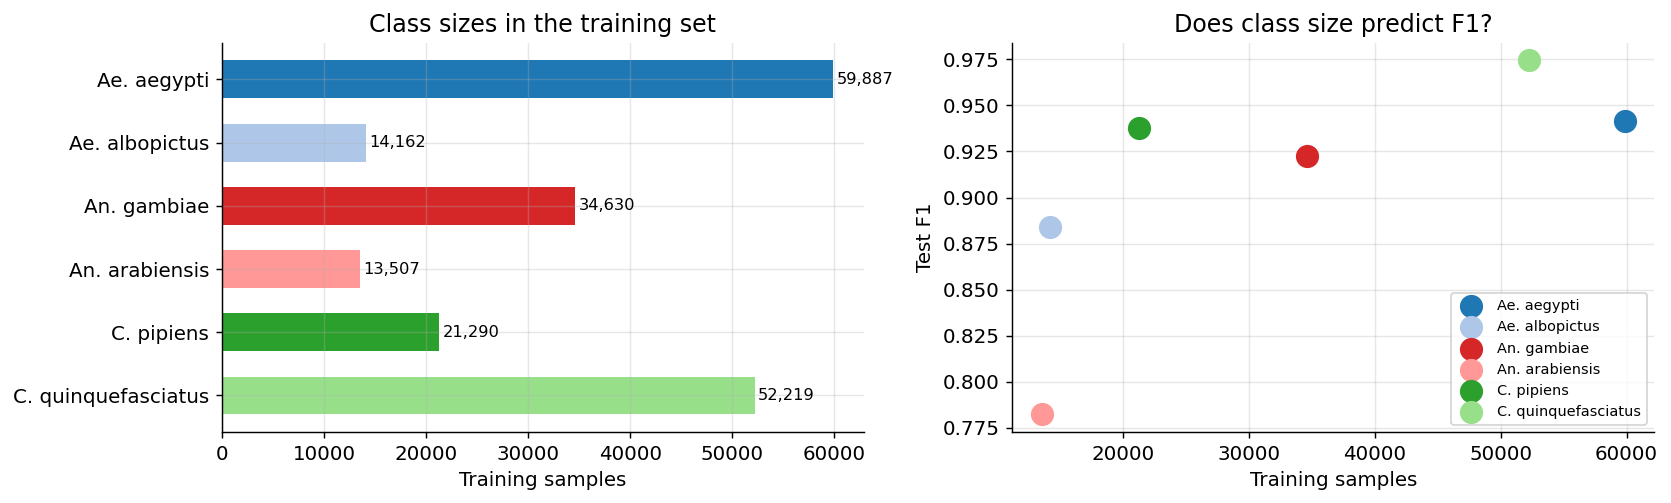

            species  train_n       f1
        Ae. aegypti    59887 0.941492
     Ae. albopictus    14162 0.884091
        An. gambiae    34630 0.922728
     An. arabiensis    13507 0.782250
         C. pipiens    21290 0.937797
C. quinquefasciatus    52219 0.974405


In [123]:
with open(METADATA) as f:
    meta = json.load(f)
with open(METRICS) as f:
    metrics = json.load(f)

train_counts  = meta['class_counts']['train']
f1_per_class  = {sp: v['f1'] for sp, v in metrics['per_class'].items()}
summary = pd.DataFrame({
    'species': SPECIES_ORDER,
    'train_n': [train_counts[s] for s in SPECIES_ORDER],
    'f1':      [f1_per_class[s] for s in SPECIES_ORDER],
})

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

ax = axes[0]
bars = ax.barh(summary['species'], summary['train_n'], color=PALETTE, height=0.6)
ax.set_xlabel('Training samples')
ax.set_title('Class sizes in the training set')
ax.invert_yaxis()
for bar, n in zip(bars, summary['train_n']):
    ax.text(bar.get_width() + 300, bar.get_y() + bar.get_height()/2,
            f'{n:,}', va='center', fontsize=9)

ax = axes[1]
for sp, color in SPECIES_COLORS.items():
    row = summary[summary['species'] == sp].iloc[0]
    ax.scatter(row['train_n'], row['f1'], s=140, color=color, zorder=3, label=sp)
ax.set_xlabel('Training samples')
ax.set_ylabel('Test F1')
ax.set_title('Does class size predict F1?')
ax.legend(fontsize=8, loc='lower right')

plt.tight_layout()
plt.savefig('fig_class_balance.png', bbox_inches='tight')
plt.show()
print(summary.to_string(index=False))

**Finding:** Class imbalance partially explains the gap, but *Ae. albopictus* has similar training size to *An. arabiensis* yet 10 F1 points higher. Something else drives *An. arabiensis* failure — the spectrograms themselves.

## 3. Confusion matrix – which species are mixed up?

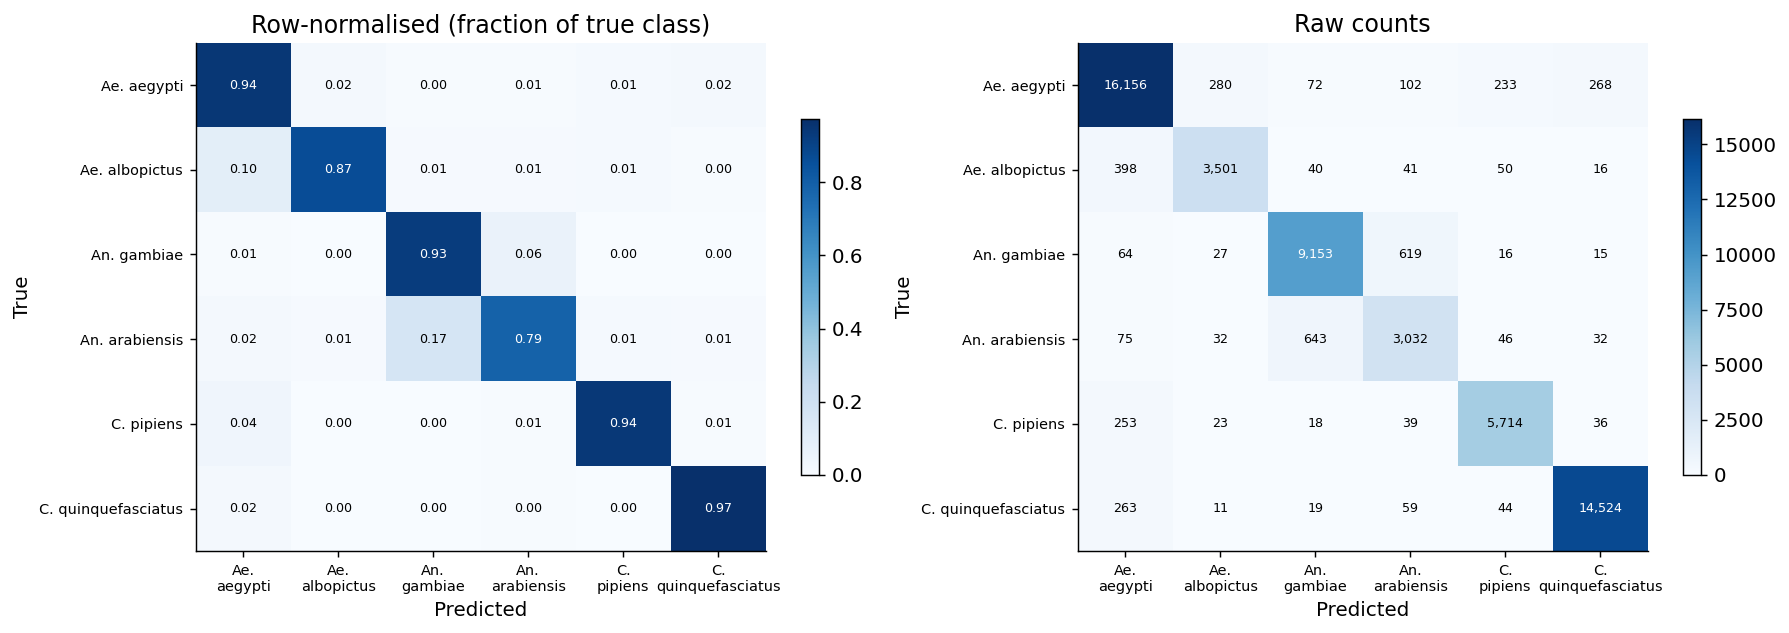

In [124]:
conf_raw  = pd.read_csv(CONFUSION, index_col=0)
conf_raw  = conf_raw.loc[SPECIES_ORDER, SPECIES_ORDER]
conf_norm = conf_raw.div(conf_raw.sum(axis=1), axis=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, data, title, fmt in [
    (axes[0], conf_norm, 'Row-normalised (fraction of true class)', '.2f'),
    (axes[1], conf_raw,  'Raw counts',                              'd'),
]:
    im = ax.imshow(data.values, cmap='Blues', vmin=0, aspect='auto')
    ax.set_xticks(range(len(SPECIES_ORDER)))
    ax.set_yticks(range(len(SPECIES_ORDER)))
    short = [s.replace('. ', '.\n') for s in SPECIES_ORDER]
    ax.set_xticklabels(short, fontsize=8)
    ax.set_yticklabels(SPECIES_ORDER, fontsize=8)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.set_title(title)
    ax.grid(False)
    for i in range(len(SPECIES_ORDER)):
        for j in range(len(SPECIES_ORDER)):
            v = data.values[i, j]
            text = f'{v:{fmt}}' if fmt == '.2f' else f'{int(v):,}'
            ax.text(j, i, text, ha='center', va='center', fontsize=7,
                    color='white' if v > data.values.max() * 0.5 else 'black')
    plt.colorbar(im, ax=ax, shrink=0.7)

plt.tight_layout()
plt.savefig('fig_confusion.png', bbox_inches='tight')
plt.show()

**Key finding:** *An. gambiae* ↔ *An. arabiensis* confusion is the dominant error. It is **asymmetric**: 16.7% of *An. arabiensis* samples are labelled as *An. gambiae*, but only 6.3% in the other direction. These are biologically closely related sibling species with nearly identical wingbeat morphology.

## 4. Confidence – is the model overconfident on its errors?

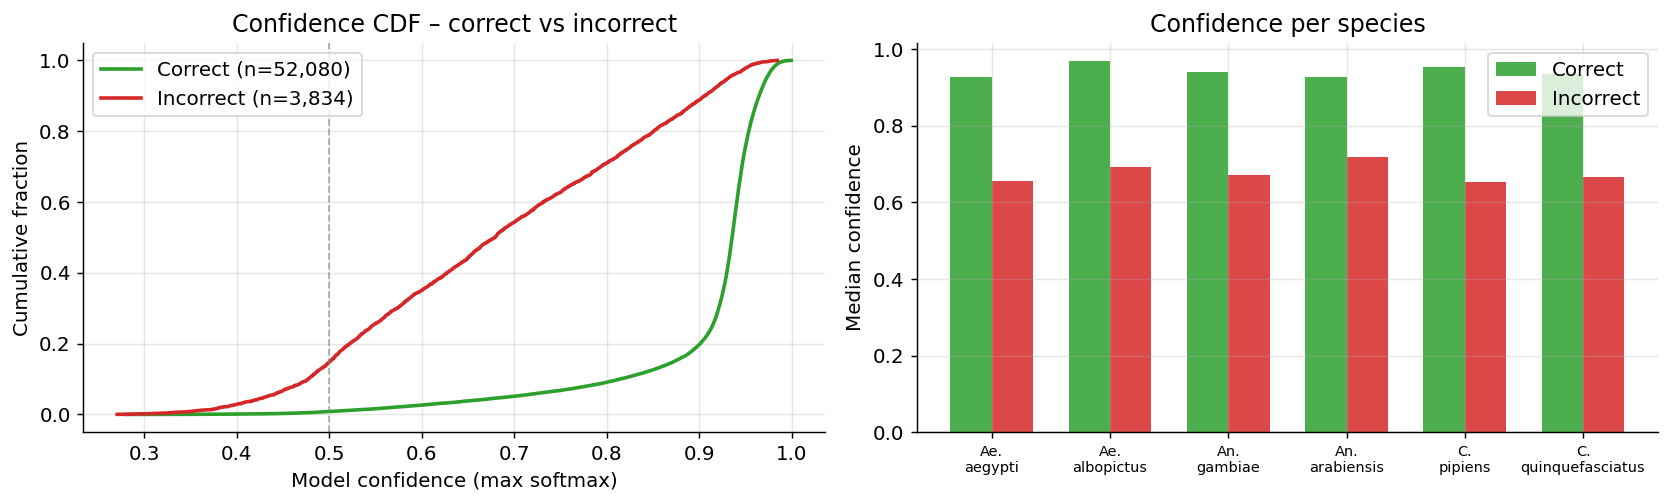

In [125]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

ax = axes[0]
for label, color, subset in [
    ('Correct',   '#2ca02c', df[df['correct']]),
    ('Incorrect', '#d62728', df[~df['correct']]),
]:
    vals = np.sort(subset['confidence'].values)
    cdf  = np.arange(1, len(vals)+1) / len(vals)
    ax.plot(vals, cdf, color=color, lw=2, label=f'{label} (n={len(vals):,})')
ax.set_xlabel('Model confidence (max softmax)')
ax.set_ylabel('Cumulative fraction')
ax.set_title('Confidence CDF – correct vs incorrect')
ax.axvline(0.5, color='gray', lw=1, ls='--', alpha=0.6)
ax.legend()

ax = axes[1]
stats = df.groupby(['true_species', 'correct'])['confidence'].median().unstack()
stats = stats.reindex(SPECIES_ORDER)
x = np.arange(len(SPECIES_ORDER))
w = 0.35
ax.bar(x - w/2, stats[True],  width=w, color='#2ca02c', alpha=0.85, label='Correct')
ax.bar(x + w/2, stats[False], width=w, color='#d62728', alpha=0.85, label='Incorrect')
ax.set_xticks(x)
ax.set_xticklabels([s.replace('. ', '.\n') for s in SPECIES_ORDER], fontsize=8)
ax.set_ylabel('Median confidence')
ax.set_title('Confidence per species')
ax.legend()

plt.tight_layout()
plt.savefig('fig_confidence.png', bbox_inches='tight')
plt.show()

**Finding:** The model is overconfident on wrong predictions. Median confidence for incorrect *An. gambiae* predictions is around 0.6–0.7 — meaning it is convinced it is right even when it is not. This is dangerous in a deployment context (e.g., disease-vector monitoring) because a high-confidence error looks identical to a high-confidence correct prediction.

## 5. Wingbeat frequency distributions

`f0_hz` is the strongest FFT bin **restricted to 200–1500 Hz** (recomputed from audio; see `results/f0_band_peak.csv`).

The original `spectral_peak_hz` was a global argmax and is often ~6 Hz junk for Anopheles — do not use it for frequency analyses.

If two species have overlapping `f0_hz` distributions, their spectrograms look alike in the wingbeat band.


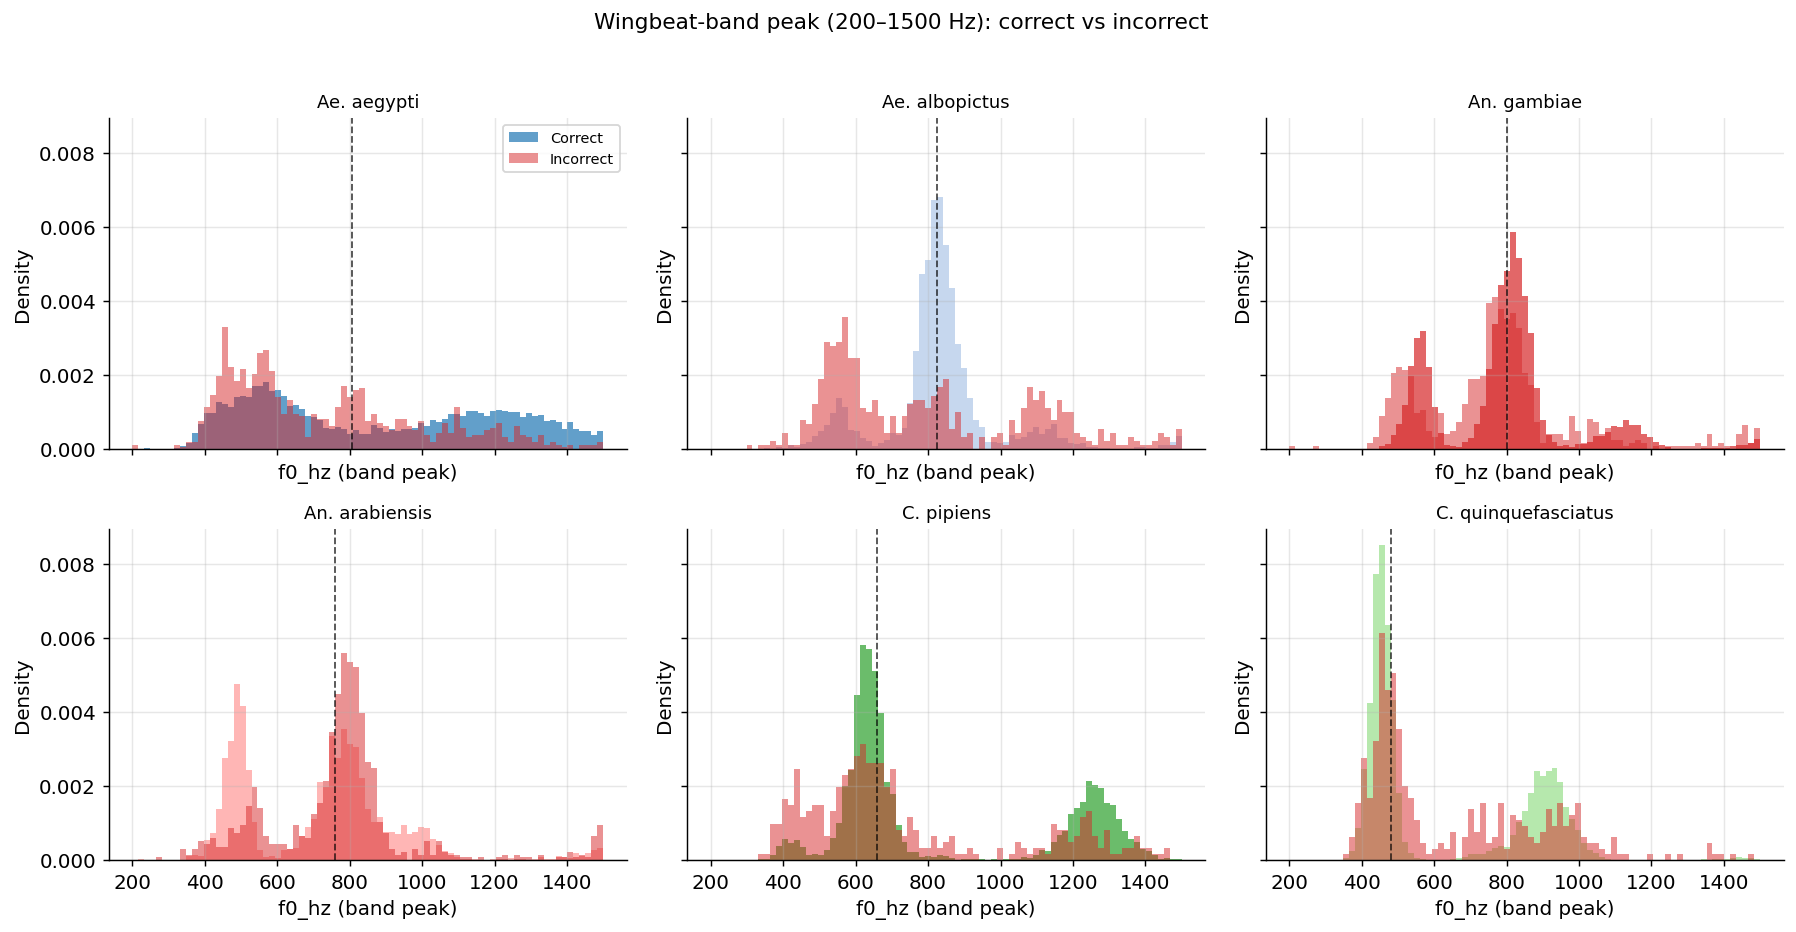

In [126]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True, sharey=True)
axes_flat = axes.flatten()
bins = np.linspace(200, 1500, 80)

for ax, sp in zip(axes_flat, SPECIES_ORDER):
    subset    = df[df['true_species'] == sp]
    correct   = subset[subset['correct']]['f0_hz']
    incorrect = subset[~subset['correct']]['f0_hz']

    ax.hist(correct,   bins=bins, density=True, color=SPECIES_COLORS[sp], alpha=0.7, label='Correct')
    ax.hist(incorrect, bins=bins, density=True, color='#d62728',           alpha=0.5,
            label='Incorrect', histtype='stepfilled')
    ax.axvline(subset['f0_hz'].median(), color='black', ls='--', lw=1, alpha=0.7)
    ax.set_title(sp, fontsize=10)
    ax.set_xlabel('f0_hz (band peak)')
    ax.set_ylabel('Density')

axes_flat[0].legend(fontsize=8)
plt.suptitle('Wingbeat-band peak (200–1500 Hz): correct vs incorrect',
             y=1.02, fontsize=12)
plt.tight_layout()
plt.savefig('fig_freq_by_species.png', bbox_inches='tight')
plt.show()


**Explanation:** Per-species density of wingbeat-band peak `f0_hz` for correct (colour) vs incorrect (red). Densities are normalized separately — tall red ≠ many errors.

**Finding:** For several species (esp. *Ae. albopictus*), errors are enriched at **atypical** peaks (often ~400–600 Hz). For the Anopheles pair, wrong and right mostly **overlap** near ~750–800 Hz — sibling confusion is not mainly “wrong frequency band.”


## 6. The Anopheles confusion – deep dive

We separate predictions into four outcomes and ask: at which frequencies does confusion peak?

outcome
Correct An. gambiae          9153
Correct An. arabiensis       3032
Confused within Anopheles    1262
Confused with other genus     307

Median f0_hz by outcome:
outcome
Confused with other genus    661.5
Confused within Anopheles    786.2
Correct An. arabiensis       747.7
Correct An. gambiae          803.1


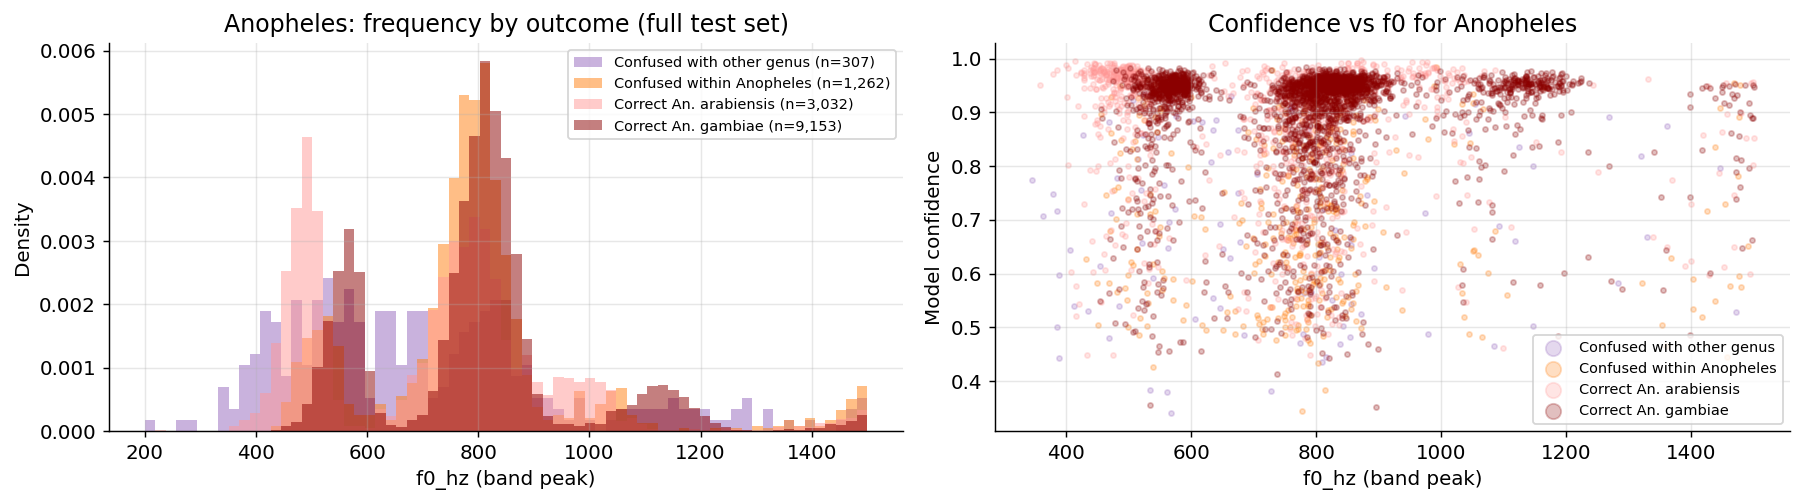

In [127]:
anoph = df[df['true_genus'] == 'Anopheles'].copy()

def outcome_label(row):
    if row['correct']:
        return f"Correct {row['true_species']}"
    elif row['predicted_genus'] == 'Anopheles':
        return 'Confused within Anopheles'
    return 'Confused with other genus'

anoph['outcome'] = anoph.apply(outcome_label, axis=1)
print(anoph['outcome'].value_counts().to_string())
print('\nMedian f0_hz by outcome:')
print(anoph.groupby('outcome')['f0_hz'].median().round(1).to_string())

outcome_colors = {
    'Correct An. gambiae':          '#8b0000',
    'Correct An. arabiensis':       '#ff9896',
    'Confused within Anopheles':    '#ff7f0e',
    'Confused with other genus':    '#9467bd',
}

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

ax = axes[0]
bins2 = np.linspace(200, 1500, 70)
for outcome, grp in anoph.groupby('outcome'):
    ax.hist(grp['f0_hz'], bins=bins2, density=True, alpha=0.5,
            label=f'{outcome} (n={len(grp):,})',
            color=outcome_colors.get(outcome, 'gray'))
ax.set_xlabel('f0_hz (band peak)')
ax.set_ylabel('Density')
ax.set_title('Anopheles: frequency by outcome (full test set)')
ax.legend(fontsize=8)

ax = axes[1]
sample = anoph.sample(min(len(anoph), 4000), random_state=42)
for outcome, grp in sample.groupby('outcome'):
    ax.scatter(grp['f0_hz'], grp['confidence'],
               s=8, alpha=0.25, color=outcome_colors.get(outcome, 'gray'), label=outcome)
ax.set_xlabel('f0_hz (band peak)')
ax.set_ylabel('Model confidence')
ax.set_title('Confidence vs f0 for Anopheles')
ax.legend(fontsize=8, markerscale=3)

plt.tight_layout()
plt.savefig('fig_anopheles_deep_dive.png', bbox_inches='tight')
plt.show()


**Explanation:** Anopheles only — `f0_hz` density by outcome (correct / confused within genus / other genus) and confidence vs frequency.

**Finding:** Most mistakes are **within Anopheles** (sibling swap), not cross-genus. Confused and correct clips largely share the same frequency region; frequency alone does not separate them cleanly.


## 7. Per-frequency accuracy in the overlap zone

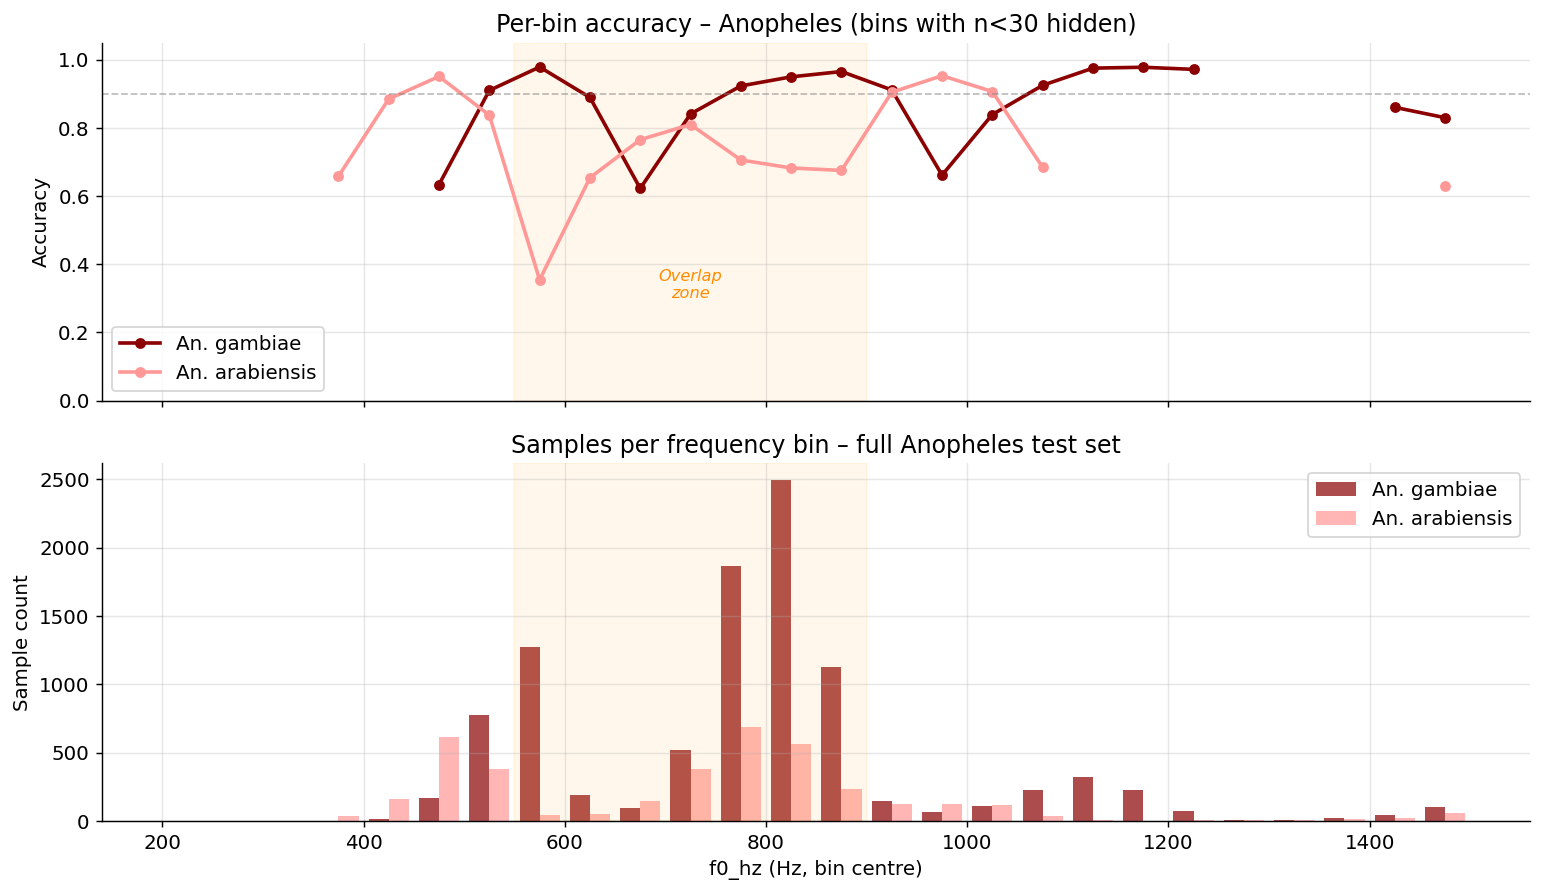

Counts in overlap zone (550, 900) :
true_species
An. arabiensis    2115
An. gambiae       7569
Accuracy in overlap:
true_species
An. arabiensis    0.710
An. gambiae       0.937


In [128]:
anoph2 = df[df['true_genus'] == 'Anopheles'].copy()
# Full Anopheles – f0_hz already restricted to 200–1500 Hz at extraction time
freq_bins = np.arange(200, 1501, 50)
anoph2['freq_bin'] = pd.cut(anoph2['f0_hz'], bins=freq_bins,
                             labels=freq_bins[:-1] + 25).astype(float)

pivot       = anoph2.groupby(['freq_bin', 'true_species'])['correct'].mean().unstack()
count_pivot = anoph2.groupby(['freq_bin', 'true_species']).size().unstack().fillna(0)

# Hide accuracy points with too few samples
MIN_N = 30

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

ax = axes[0]
for sp, color in [('An. gambiae', '#8b0000'), ('An. arabiensis', '#ff9896')]:
    if sp not in pivot.columns:
        continue
    y = pivot[sp].copy()
    y[count_pivot[sp] < MIN_N] = np.nan
    ax.plot(y.index, y, marker='o', color=color, lw=2, ms=5, label=sp)
ax.axhline(0.9, color='gray', ls='--', lw=1, alpha=0.5)
ax.set_ylabel('Accuracy')
ax.set_title(f'Per-bin accuracy – Anopheles (bins with n<{MIN_N} hidden)')
ax.legend()
ax.set_ylim(0, 1.05)

ax = axes[1]
bar_w = 20
for i, (sp, color) in enumerate([('An. gambiae', '#8b0000'), ('An. arabiensis', '#ff9896')]):
    if sp in count_pivot.columns:
        ax.bar(count_pivot.index + (i - 0.5)*bar_w, count_pivot[sp],
               width=bar_w, color=color, alpha=0.7, label=sp)
ax.set_xlabel('f0_hz (Hz, bin centre)')
ax.set_ylabel('Sample count')
ax.set_title('Samples per frequency bin – full Anopheles test set')
ax.legend()

OVERLAP = (550, 900)  # mass overlap of the two Anopheles f0 distributions
for ax in axes:
    ax.axvspan(*OVERLAP, alpha=0.08, color='orange')

axes[0].text(sum(OVERLAP)/2, 0.3, 'Overlap\nzone', ha='center', fontsize=9,
             color='darkorange', style='italic')

plt.tight_layout()
plt.savefig('fig_freq_accuracy.png', bbox_inches='tight')
plt.show()

print('Counts in overlap zone', OVERLAP, ':')
in_ov = anoph2[anoph2['f0_hz'].between(*OVERLAP)]
print(in_ov.groupby('true_species').size().to_string())
print('Accuracy in overlap:')
print(in_ov.groupby('true_species')['correct'].mean().round(3).to_string())


**Explanation:** Accuracy and sample counts vs `f0_hz` bin for both Anopheles (bins with tiny *n* hidden). Orange band = mass overlap (~550–900 Hz).

**Finding:** In the overlap zone, *gambiae* stays high (~0.94) while *arabiensis* drops (~0.71). Sparse bins can show fake 0%/100% spikes — trust high-*n* bins only.


## 7b. H2 – Do errors cluster where a clip's frequency is atypical for its species?

**Hypothesis:** Each species has a characteristic wingbeat frequency. Clips whose `f0_hz` drifts far from their species median are harder to classify.

Uses **all** test clips (`f0_hz` = strongest FFT bin in 200–1500 Hz). No junk-peak filter needed.


Per-species median f0_hz (full test set):
true_species
Ae. aegypti            807.7
Ae. albopictus         824.6
An. gambiae            801.5
An. arabiensis         758.5
C. pipiens             660.0
C. quinquefasciatus    480.0

n per species:
true_species
Ae. aegypti            17111
Ae. albopictus          4046
An. gambiae             9894
An. arabiensis          3860
C. pipiens              6083
C. quinquefasciatus    14920


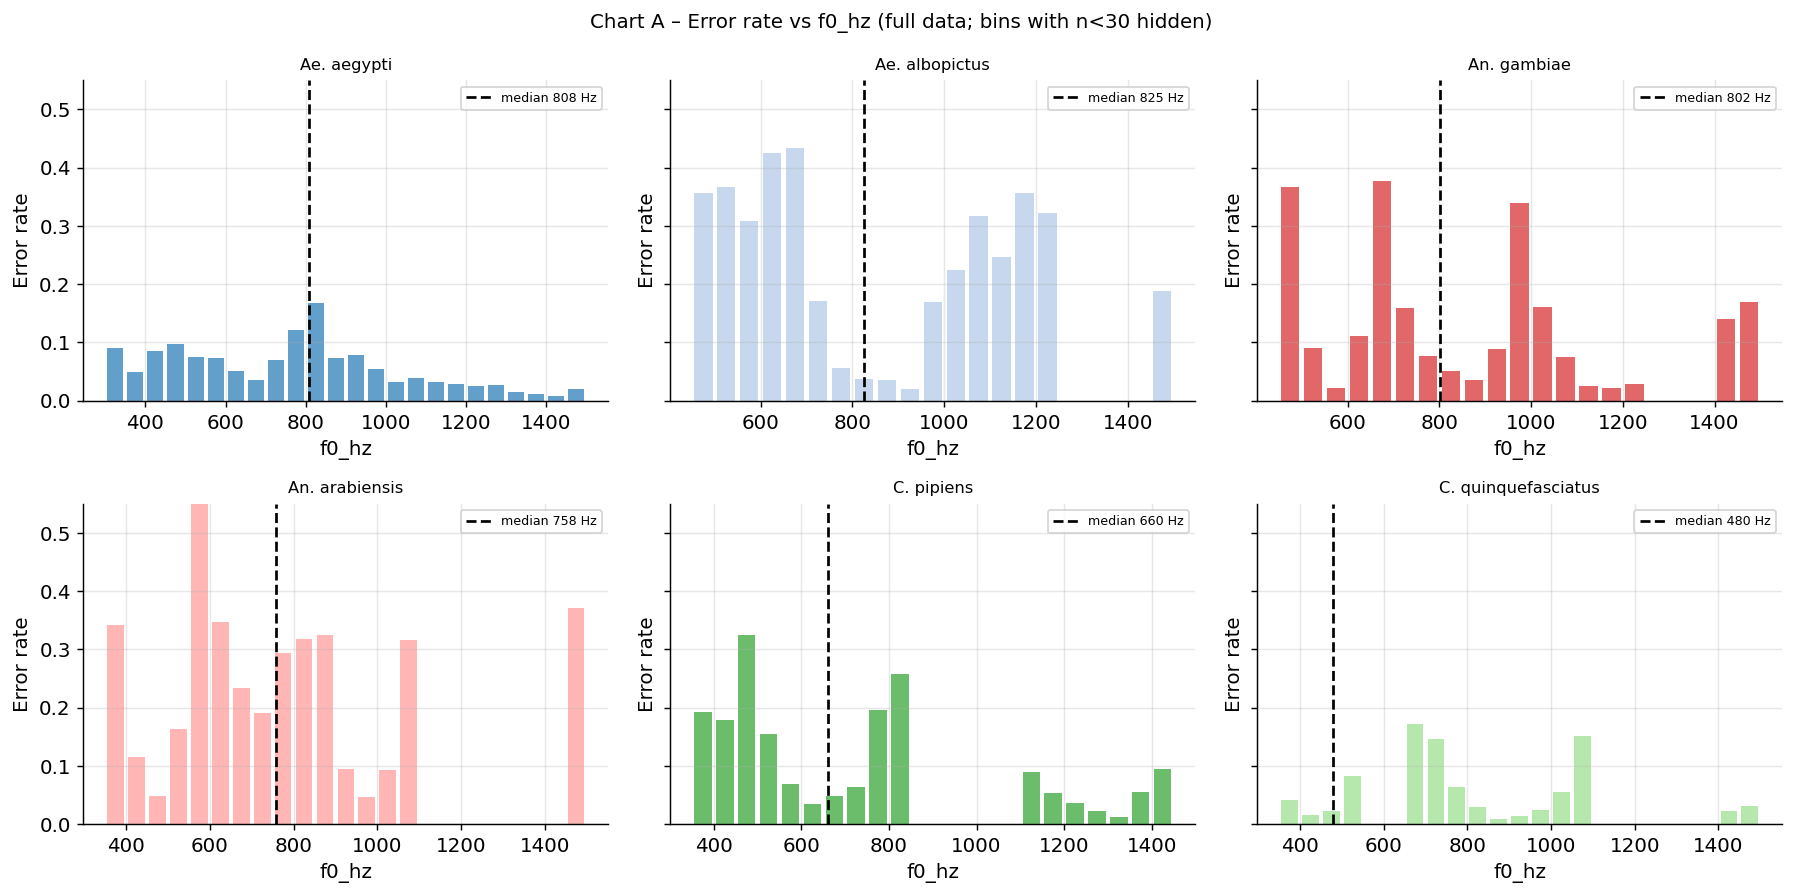

In [129]:
# ── Setup: atypicality on FULL test set via f0_hz ────────────────────────────
h2 = df.copy()

species_median = h2.groupby('true_species')['f0_hz'].median()
h2['sp_median']  = h2['true_species'].map(species_median)
h2['delta_hz']   = h2['f0_hz'] - h2['sp_median']
h2['abs_delta']  = h2['delta_hz'].abs()

print("Per-species median f0_hz (full test set):")
print(species_median.reindex(SPECIES_ORDER).round(1).to_string())
print("\nn per species:")
print(h2.groupby('true_species').size().reindex(SPECIES_ORDER).to_string())

# ── Chart A: error rate vs f0_hz per species ─────────────────────────────────
BIN_W = 50
MIN_N = 30
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharey=True)

for ax, sp in zip(axes.flatten(), SPECIES_ORDER):
    sub    = h2[h2['true_species'] == sp].copy()
    lo     = (sub['f0_hz'].min() // BIN_W) * BIN_W
    hi     = (sub['f0_hz'].max() // BIN_W + 1) * BIN_W
    edges  = np.arange(lo, hi + BIN_W, BIN_W)
    labels = edges[:-1] + BIN_W / 2

    sub['bin'] = pd.cut(sub['f0_hz'], bins=edges, labels=labels).astype(float)
    agg = sub.groupby('bin').agg(err_rate=('correct', lambda x: 1 - x.mean()),
                                  n=('correct', 'size')).reset_index()
    agg = agg[agg['n'] >= MIN_N]

    color = SPECIES_COLORS[sp]
    ax.bar(agg['bin'], agg['err_rate'], width=BIN_W * 0.8, color=color, alpha=0.7)
    ax.axvline(species_median[sp], color='black', lw=1.5, ls='--',
               label=f'median {species_median[sp]:.0f} Hz')
    ax.set_title(sp, fontsize=9)
    ax.set_xlabel('f0_hz')
    ax.set_ylabel('Error rate')
    ax.set_ylim(0, 0.55)
    ax.legend(fontsize=7)

plt.suptitle(f'Chart A – Error rate vs f0_hz (full data; bins with n<{MIN_N} hidden)', fontsize=11)
plt.tight_layout()
plt.savefig('fig_h2_error_vs_f0.png', bbox_inches='tight')
plt.show()


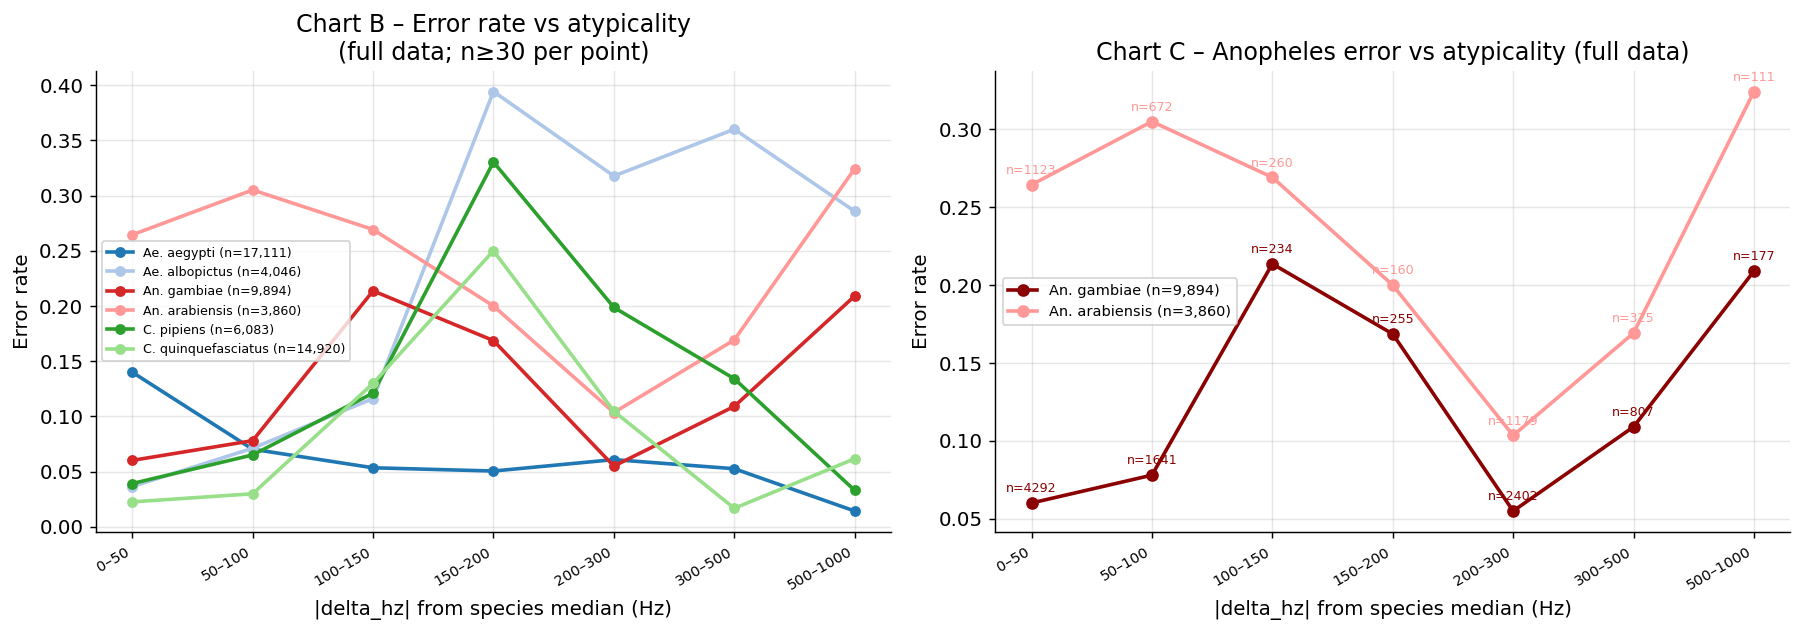


H2 stats – typical (bottom 50% |delta|) vs atypical (top 50% |delta|):
            species     n  median_f0_hz  typical_err  atypical_err  lift
        Ae. aegypti 17111         807.7        0.067         0.045  0.68
     Ae. albopictus  4046         824.6        0.037         0.233  6.32
        An. gambiae  9894         801.5        0.061         0.089  1.45
     An. arabiensis  3860         758.5        0.285         0.144  0.51
         C. pipiens  6083         660.0        0.041         0.080  1.95
C. quinquefasciatus 14920         480.0        0.023         0.031  1.36

lift = atypical_err / typical_err  (>1 supports H2; <1 is opposite)


In [130]:
# ── Chart B: error rate vs |delta_hz| (atypicality), one curve per species ───
DELTA_EDGES = [0, 50, 100, 150, 200, 300, 500, 1000]
delta_labels = [f'{DELTA_EDGES[i]}–{DELTA_EDGES[i+1]}' for i in range(len(DELTA_EDGES)-1)]
MIN_N = 30

h2['delta_bin'] = pd.cut(h2['abs_delta'], bins=DELTA_EDGES, labels=delta_labels)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
x_pos = {lab: i for i, lab in enumerate(delta_labels)}

ax = axes[0]
for sp in SPECIES_ORDER:
    sub = h2[h2['true_species'] == sp]
    agg = sub.groupby('delta_bin', observed=True).agg(
        err_rate=('correct', lambda x: 1 - x.mean()),
        n=('correct', 'size')
    )
    agg = agg[agg['n'] >= MIN_N]
    xs = [x_pos[str(i)] for i in agg.index]
    ax.plot(xs, agg['err_rate'], marker='o', ms=5,
            color=SPECIES_COLORS[sp], lw=2, label=f"{sp} (n={len(sub):,})")

ax.set_xticks(range(len(delta_labels)))
ax.set_xticklabels(delta_labels, rotation=30, ha='right', fontsize=8)
ax.set_xlabel('|delta_hz| from species median (Hz)')
ax.set_ylabel('Error rate')
ax.set_title(f'Chart B – Error rate vs atypicality\n(full data; n≥{MIN_N} per point)')
ax.legend(fontsize=7)

ax = axes[1]
for sp, color in [('An. gambiae', '#8b0000'), ('An. arabiensis', '#ff9896')]:
    sub = h2[h2['true_species'] == sp]
    agg = sub.groupby('delta_bin', observed=True).agg(
        err_rate=('correct', lambda x: 1 - x.mean()),
        n=('correct', 'size')
    )
    agg = agg[agg['n'] >= MIN_N]
    xs = [x_pos[str(i)] for i in agg.index]
    ax.plot(xs, agg['err_rate'], marker='o', ms=6, color=color, lw=2,
            label=f'{sp} (n={len(sub):,})')
    for x, (_, row) in zip(xs, agg.iterrows()):
        ax.annotate(f"n={int(row['n'])}", (x, row['err_rate']),
                    textcoords='offset points', xytext=(0, 6),
                    ha='center', fontsize=7, color=color)

ax.set_xticks(range(len(delta_labels)))
ax.set_xticklabels(delta_labels, rotation=30, ha='right', fontsize=8)
ax.set_xlabel('|delta_hz| from species median (Hz)')
ax.set_ylabel('Error rate')
ax.set_title('Chart C – Anopheles error vs atypicality (full data)')
ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig('fig_h2_error_vs_atypicality.png', bbox_inches='tight')
plt.show()

rows = []
for sp in SPECIES_ORDER:
    sub = h2[h2['true_species'] == sp]
    thr = sub['abs_delta'].median()
    typical = sub[sub['abs_delta'] <= thr]
    atypic  = sub[sub['abs_delta'] > thr]
    te = 1 - typical['correct'].mean()
    ae = 1 - atypic['correct'].mean()
    rows.append({
        'species': sp,
        'n': len(sub),
        'median_f0_hz': round(species_median[sp], 1),
        'typical_err': round(te, 3),
        'atypical_err': round(ae, 3),
        'lift': round(ae / max(te, 1e-6), 2),
    })

stats_table = pd.DataFrame(rows)
print('\nH2 stats – typical (bottom 50% |delta|) vs atypical (top 50% |delta|):')
print(stats_table.to_string(index=False))
print('\nlift = atypical_err / typical_err  (>1 supports H2; <1 is opposite)')


**H2 finding (full data, `f0_hz`):**  
With all test clips, H2 is **mixed**, not uniformly supported:
- **Supported:** *Ae. albopictus*, *C. pipiens*, *An. gambiae*, *C. quinquefasciatus* (lift > 1).
- **Not supported / reversed:** *An. arabiensis* and *Ae. aegypti* (atypical clips are *easier* or no worse).

So “far from species median ⇒ harder” is **not** the main Anopheles story for *arabiensis*. Their high baseline error sits near their own centre too. Next: H6 (event duration) or H7 (background / `raw_rms`), or Phase II attention.


## 8. Real spectrogram analysis

We read WAV files directly from `archive.zip` (no extraction needed) and compute log-Mel spectrograms using the **exact same pipeline as the trained model**.

For each species we show correctly classified samples. Then we zoom into the *Anopheles* confusion: placing a confused sample next to a correctly classified one at the same frequency to see what the model could not distinguish.

In [131]:
import zipfile, io
from math import gcd
from pathlib import Path

import numpy as np
import soundfile as sf
from scipy.signal import stft

# ── archive.zip lives next to the repo (workspace root) ────────────────
ZIP_PATH = Path(r'D:\AI and Vis\archive.zip')
print(f"ZIP_PATH: {ZIP_PATH}")
print(f"ZIP_PATH exists: {ZIP_PATH.exists()}")

# ── Audio / spectrogram parameters (must match the trained model exactly) ────
SR, N_FFT, HOP, N_MELS = 8000, 512, 32, 128
F_MIN, F_MAX, TOP_DB    = 0.0, 4000.0, 80.0
N_SAMPLES               = round(SR * 0.65)   # 5200

def hz_to_mel(hz):  return 2595 * np.log10(1 + hz / 700)
def mel_to_hz(mel): return 700 * (10 ** (mel / 2595) - 1)

def _build_mel_fb():
    mel_pts = np.linspace(hz_to_mel(F_MIN), hz_to_mel(F_MAX), N_MELS + 2)
    hz_pts  = mel_to_hz(mel_pts)
    bins    = np.floor((N_FFT + 1) * hz_pts / SR).astype(int)
    fb      = np.zeros((N_MELS, N_FFT // 2 + 1))
    for m in range(1, N_MELS + 1):
        lo, mid, hi = bins[m-1], bins[m], bins[m+1]
        for k in range(lo, mid):
            if mid > lo: fb[m-1, k] = (k - lo) / (mid - lo)
        for k in range(mid, hi):
            if hi  > mid: fb[m-1, k] = (hi - k) / (hi - mid)
    return fb

MEL_FB = _build_mel_fb()

def compute_logmel(signal):
    signal = np.asarray(signal, dtype=np.float32)
    signal = signal - signal.mean()
    _, _, Zxx = stft(signal, fs=SR, nperseg=N_FFT, noverlap=N_FFT - HOP, window='hann')
    mel_s   = MEL_FB @ np.abs(Zxx) ** 2
    log_mel = 10 * np.log10(np.maximum(mel_s, 1e-10))
    return np.maximum(log_mel, log_mel.max() - TOP_DB)

def load_wav_from_zip(zf, relative_path):
    data  = zf.read(relative_path)
    audio, orig_sr = sf.read(io.BytesIO(data), dtype='float32', always_2d=True)
    mono = audio.mean(axis=1)
    if orig_sr != SR:
        from scipy.signal import resample_poly
        d = gcd(orig_sr, SR)
        mono = resample_poly(mono, SR // d, orig_sr // d).astype(np.float32)
    n = N_SAMPLES
    if len(mono) > n:
        start = (len(mono) - n) // 2
        mono  = mono[start:start + n]
    elif len(mono) < n:
        left = (n - len(mono)) // 2
        mono = np.pad(mono, (left, n - len(mono) - left))
    return mono.astype(np.float32)

print(f"Mel filterbank shape: {MEL_FB.shape}")

ZIP_PATH: D:\AI and Vis\archive.zip
ZIP_PATH exists: True
Mel filterbank shape: (128, 257)


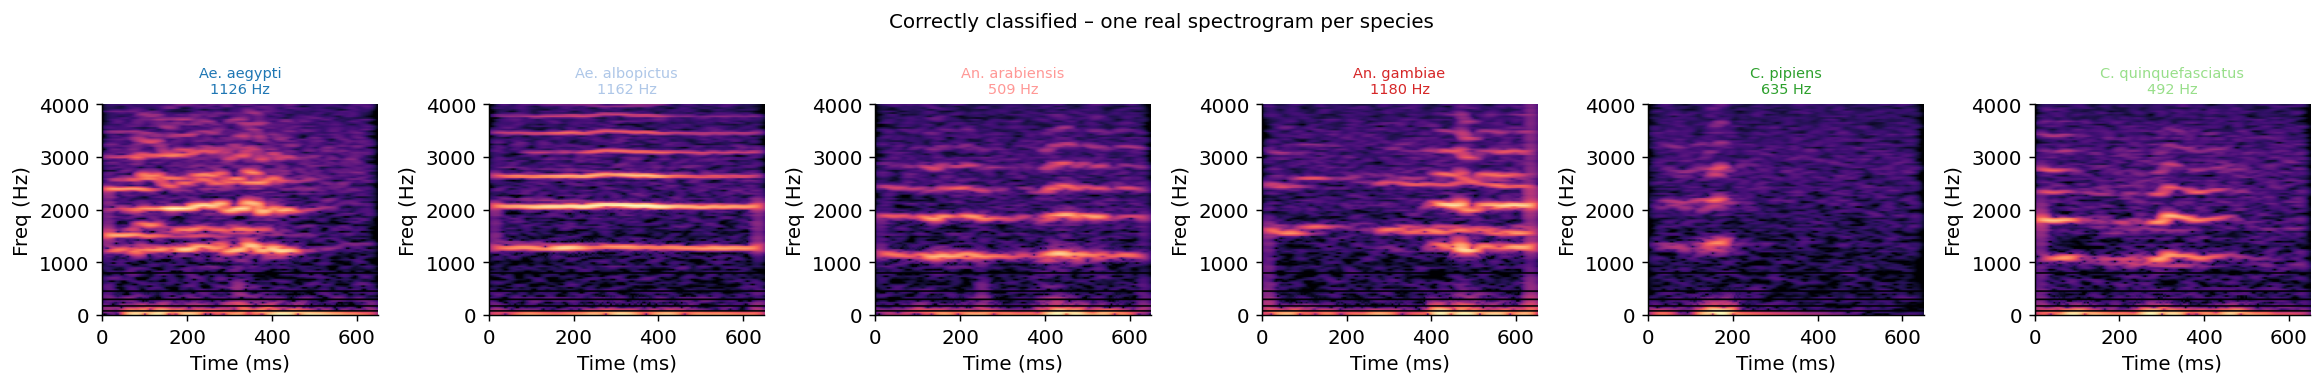

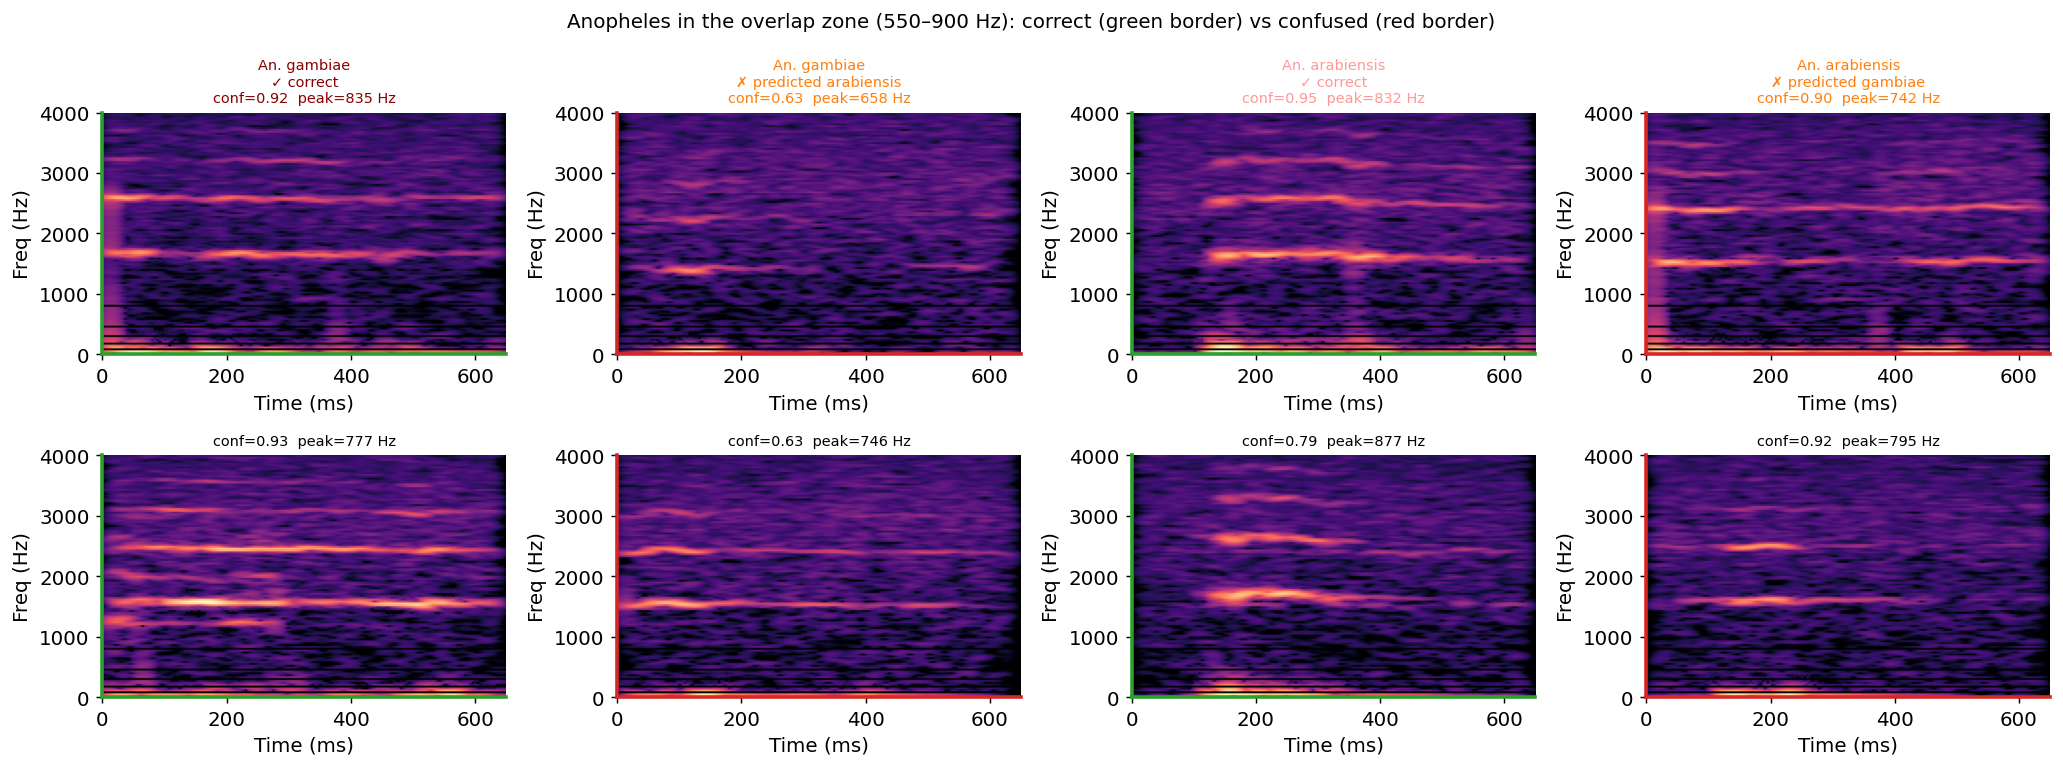

In [132]:
# ── 8a. One representative correct spectrogram per species ───────────────────
N_PER_SPECIES = 1   # increase if you want more examples

sample_rows = (
    df[df['correct']]
    .groupby('true_species', group_keys=False)
    .apply(lambda g: g.sample(N_PER_SPECIES, random_state=42))
)

fig, axes = plt.subplots(1, 6, figsize=(18, 3))
with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
    for ax, (_, row) in zip(axes, sample_rows.iterrows()):
        sig  = load_wav_from_zip(zf, row['relative_path'])
        spec = compute_logmel(sig)
        ax.imshow(spec, origin='lower', aspect='auto', cmap='magma',
                  extent=[0, 650, F_MIN, F_MAX])
        ax.set_title(f"{row['true_species']}\n{row['f0_hz']:.0f} Hz",
                     fontsize=8, color=SPECIES_COLORS[row['true_species']])
        ax.set_xlabel('Time (ms)')
        ax.set_ylabel('Freq (Hz)')
        ax.grid(False)

plt.suptitle('Correctly classified – one real spectrogram per species', fontsize=11)
plt.tight_layout()
plt.savefig('fig_real_spectrograms_correct.png', bbox_inches='tight')
plt.show()

# ── 8b. Anopheles confusion: correct vs confused side-by-side ────────────────
# Pick samples in the overlap zone (400–650 Hz) for maximum visual impact
overlap_mask = df['f0_hz'].between(550, 900)  # Anopheles f0 mass overlap

anoph_correct_gam = df[df['true_species'].eq('An. gambiae')   & df['correct'] & overlap_mask]
anoph_correct_ara = df[df['true_species'].eq('An. arabiensis') & df['correct'] & overlap_mask]
anoph_wrong_ara   = df[df['true_species'].eq('An. arabiensis') & ~df['correct']
                       & df['predicted_species'].eq('An. gambiae') & overlap_mask]
anoph_wrong_gam   = df[df['true_species'].eq('An. gambiae')   & ~df['correct']
                       & df['predicted_species'].eq('An. arabiensis') & overlap_mask]

picks = [
    (anoph_correct_gam, 'An. gambiae\n✓ correct',         '#8b0000'),
    (anoph_wrong_gam,   'An. gambiae\n✗ predicted arabiensis', '#ff7f0e'),
    (anoph_correct_ara, 'An. arabiensis\n✓ correct',       '#ff9896'),
    (anoph_wrong_ara,   'An. arabiensis\n✗ predicted gambiae',  '#ff7f0e'),
]

fig, axes = plt.subplots(2, 4, figsize=(16, 6))
with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
    for col, (pool, label, color) in enumerate(picks):
        for row_idx in range(2):
            ax   = axes[row_idx][col]
            row  = pool.sample(1, random_state=row_idx * 7 + col).iloc[0]
            sig  = load_wav_from_zip(zf, row['relative_path'])
            spec = compute_logmel(sig)
            ax.imshow(spec, origin='lower', aspect='auto', cmap='magma',
                      extent=[0, 650, F_MIN, F_MAX])
            if row_idx == 0:
                ax.set_title(f'{label}\nconf={row["confidence"]:.2f}  peak={row["f0_hz"]:.0f} Hz',
                             fontsize=8, color=color)
            else:
                ax.set_title(f'conf={row["confidence"]:.2f}  peak={row["f0_hz"]:.0f} Hz',
                             fontsize=8)
            ax.set_xlabel('Time (ms)')
            ax.set_ylabel('Freq (Hz)')
            ax.grid(False)
            border_color = '#d62728' if '✗' in label else '#2ca02c'
            for spine in ax.spines.values():
                spine.set_edgecolor(border_color)
                spine.set_linewidth(2)

plt.suptitle('Anopheles in the overlap zone (550–900 Hz): correct (green border) vs confused (red border)',
             fontsize=11)
plt.tight_layout()
plt.savefig('fig_anopheles_spectrograms.png', bbox_inches='tight')
plt.show()


**Explanation:** Example real spectrograms — one correct per species, then Anopheles correct vs confused side-by-side in the overlap zone.

**Finding:** At matched overlap frequencies, correct and confused Anopheles spectrograms look very similar by eye. The failure is subtle, not a gross spectrogram mismatch.


## 8b. Listen – can you hear the difference?

Play the samples below. If you cannot reliably tell *An. gambiae* from *An. arabiensis* by ear, the model's confusion is acoustically justified.

In [133]:
from IPython.display import Audio, display

overlap_mask = df['f0_hz'].between(550, 900)

listen_cases = {
    'An. gambiae   – CORRECT (overlap zone)':       df[df['true_species'].eq('An. gambiae')    & df['correct']  & overlap_mask],
    'An. gambiae   – WRONG → predicted arabiensis': df[df['true_species'].eq('An. gambiae')    & ~df['correct'] & df['predicted_species'].eq('An. arabiensis') & overlap_mask],
    'An. arabiensis – CORRECT (overlap zone)':      df[df['true_species'].eq('An. arabiensis') & df['correct']  & overlap_mask],
    'An. arabiensis – WRONG → predicted gambiae':   df[df['true_species'].eq('An. arabiensis') & ~df['correct'] & df['predicted_species'].eq('An. gambiae')    & overlap_mask],
}

with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
    for label, pool in listen_cases.items():
        row = pool.sample(1, random_state=99).iloc[0]
        sig = load_wav_from_zip(zf, row['relative_path'])
        print(f"\n{label}")
        print(f"  peak={row['f0_hz']:.0f} Hz  conf={row['confidence']:.2f}")
        display(Audio(sig, rate=SR))



An. gambiae   – CORRECT (overlap zone)
  peak=805 Hz  conf=0.95



An. gambiae   – WRONG → predicted arabiensis
  peak=672 Hz  conf=0.91



An. arabiensis – CORRECT (overlap zone)
  peak=852 Hz  conf=1.00



An. arabiensis – WRONG → predicted gambiae
  peak=742 Hz  conf=0.48


**Explanation:** Play one correct and one confused clip per Anopheles species from the overlap zone.

**Finding:** Mistakes can still sound (and score) like confident predictions (e.g. high-confidence wrong). Listening does not make the sibling swap obvious — consistent with weak spectrogram differences.


## 8c. Average spectrograms & difference maps

Individual samples are noisy. Averaging over hundreds of samples cancels the noise and reveals any **systematic** difference in energy distribution between correct and confused predictions.

Computing average spectrograms...
  An. gambiae correct: 50 samples
  An. gambiae confused: 50 samples
  An. arabiensis correct: 50 samples
  An. arabiensis confused: 50 samples


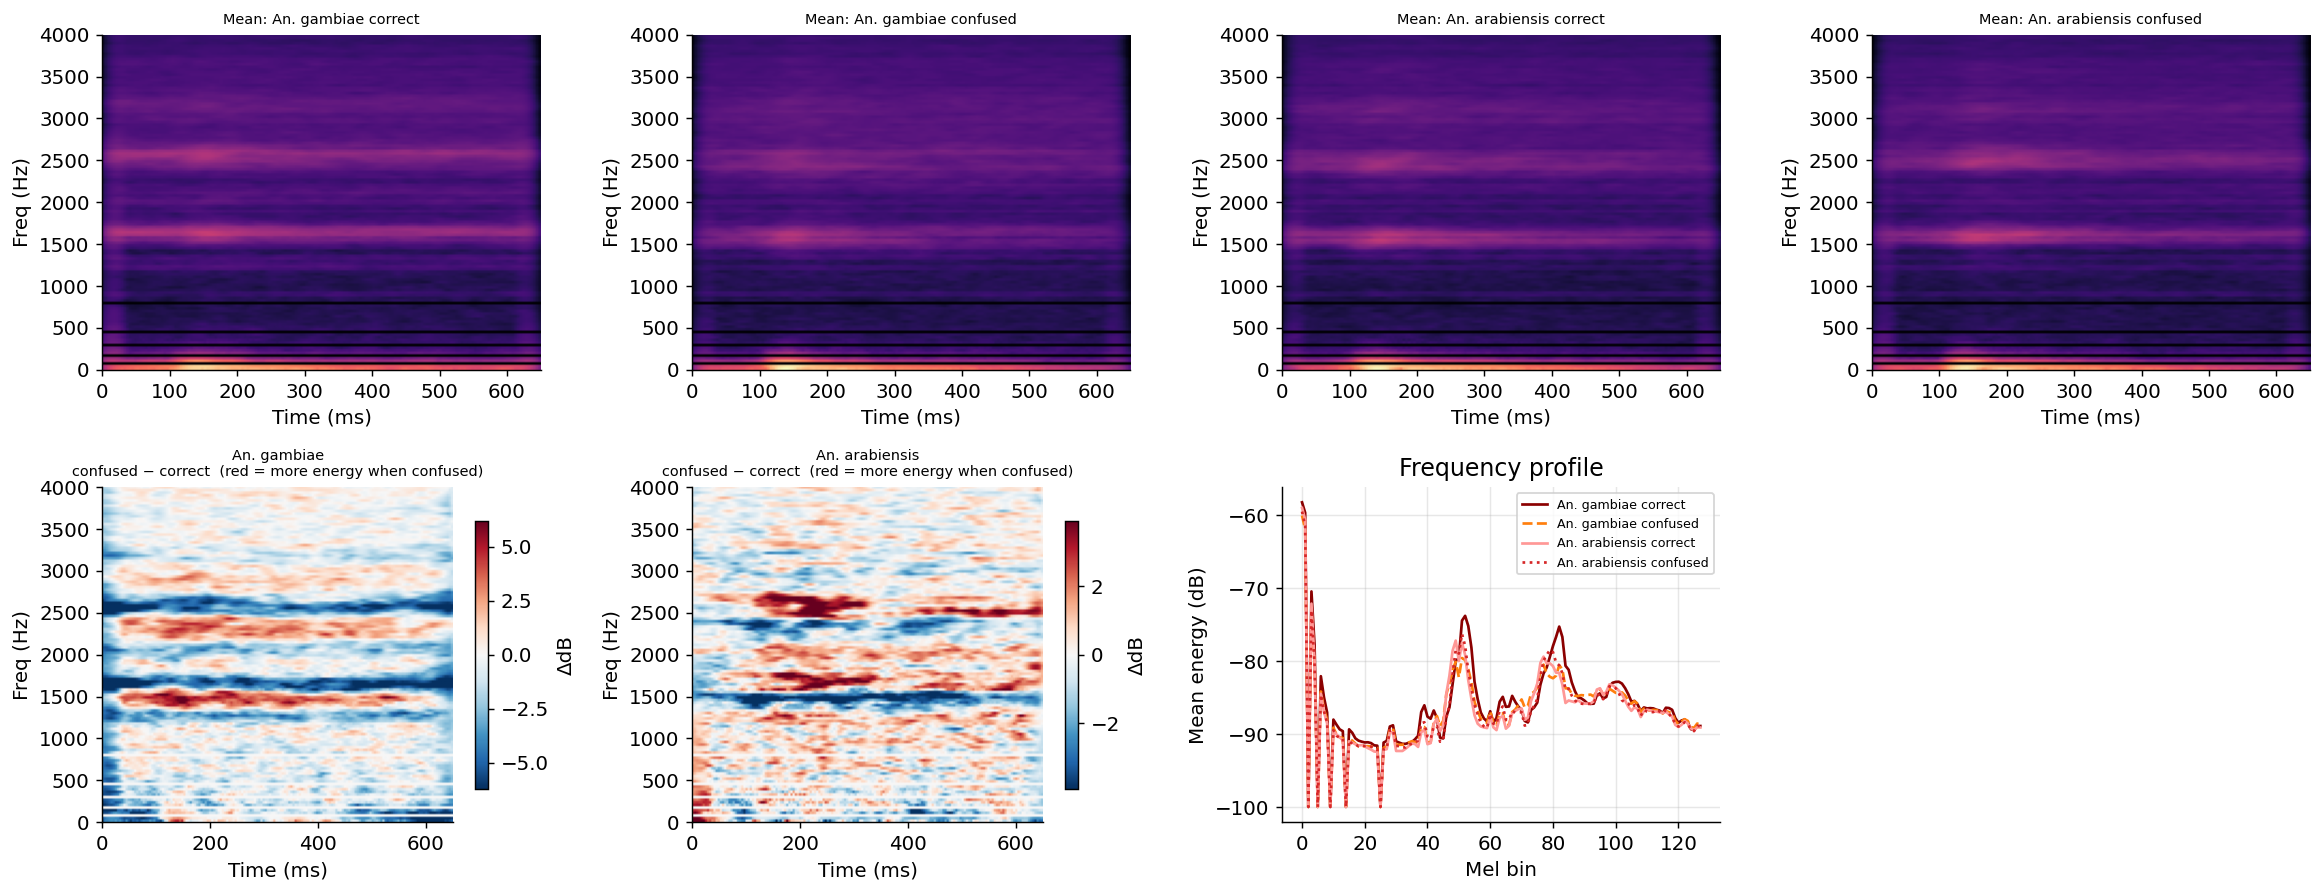

In [134]:
overlap_mask = df['f0_hz'].between(550, 900)

N_AVG = 50   # start small; raise to 300 for final run

categories = {
    'An. gambiae correct':    df[df['true_species'].eq('An. gambiae')    & df['correct']  & overlap_mask],
    'An. gambiae confused':   df[df['true_species'].eq('An. gambiae')    & ~df['correct'] & df['predicted_species'].eq('An. arabiensis') & overlap_mask],
    'An. arabiensis correct': df[df['true_species'].eq('An. arabiensis') & df['correct']  & overlap_mask],
    'An. arabiensis confused':df[df['true_species'].eq('An. arabiensis') & ~df['correct'] & df['predicted_species'].eq('An. gambiae')    & overlap_mask],
}

print("Computing average spectrograms...")
avg_specs = {}
with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
    for label, pool in categories.items():
        rows  = pool.sample(min(N_AVG, len(pool)), random_state=0)
        stack = []
        for _, row in rows.iterrows():
            try:
                sig = load_wav_from_zip(zf, row['relative_path'])
                stack.append(compute_logmel(sig))
            except Exception:
                pass
        avg_specs[label] = np.mean(stack, axis=0)
        print(f"  {label}: {len(stack)} samples")

# ── 4 average spectrograms ───────────────────────────────────────────────────
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
vmin = min(s.min() for s in avg_specs.values())
vmax = max(s.max() for s in avg_specs.values())

for col, label in enumerate(categories):
    ax = axes[0][col]
    ax.imshow(avg_specs[label], origin='lower', aspect='auto', cmap='magma',
              vmin=vmin, vmax=vmax, extent=[0, 650, F_MIN, F_MAX])
    ax.set_title(f'Mean: {label}', fontsize=8)
    ax.set_xlabel('Time (ms)'); ax.set_ylabel('Freq (Hz)'); ax.grid(False)

# ── 2 difference maps (confused − correct) ──────────────────────────────────
for col, (sp, c_lbl, w_lbl) in enumerate([
    ('An. gambiae',    'An. gambiae correct',    'An. gambiae confused'),
    ('An. arabiensis', 'An. arabiensis correct', 'An. arabiensis confused'),
]):
    ax   = axes[1][col]
    diff = avg_specs[w_lbl] - avg_specs[c_lbl]
    lim  = np.percentile(np.abs(diff), 98)
    im   = ax.imshow(diff, origin='lower', aspect='auto', cmap='RdBu_r',
                     vmin=-lim, vmax=lim, extent=[0, 650, F_MIN, F_MAX])
    ax.set_title(f'{sp}\nconfused − correct  (red = more energy when confused)', fontsize=8)
    ax.set_xlabel('Time (ms)'); ax.set_ylabel('Freq (Hz)'); ax.grid(False)
    plt.colorbar(im, ax=ax, shrink=0.8, label='ΔdB')

# ── frequency profiles ───────────────────────────────────────────────────────
ax = axes[1][2]
styles = [('#8b0000','-'), ('#ff7f0e','--'), ('#ff9896','-'), ('#d62728',':')]
for (label, _), (color, ls) in zip(categories.items(), styles):
    ax.plot(avg_specs[label].mean(axis=1), label=label, color=color, ls=ls, lw=1.5)
ax.set_xlabel('Mel bin'); ax.set_ylabel('Mean energy (dB)')
ax.set_title('Frequency profile'); ax.legend(fontsize=7)

axes[1][3].axis('off')   # spare panel

plt.tight_layout()
plt.savefig('fig_avg_spectrograms.png', bbox_inches='tight')
plt.show()


**Explanation:** Mean log-Mel spectrograms for correct vs confused Anopheles in the 550–900 Hz overlap, plus `confused − correct` maps and mean frequency profiles.

**Finding:** Averages look almost alike; Δ maps only show weak harmonic stripes. **No obvious visual cue** separates confused from correct in input space — need finer features or model internals.


## 9. Training curve

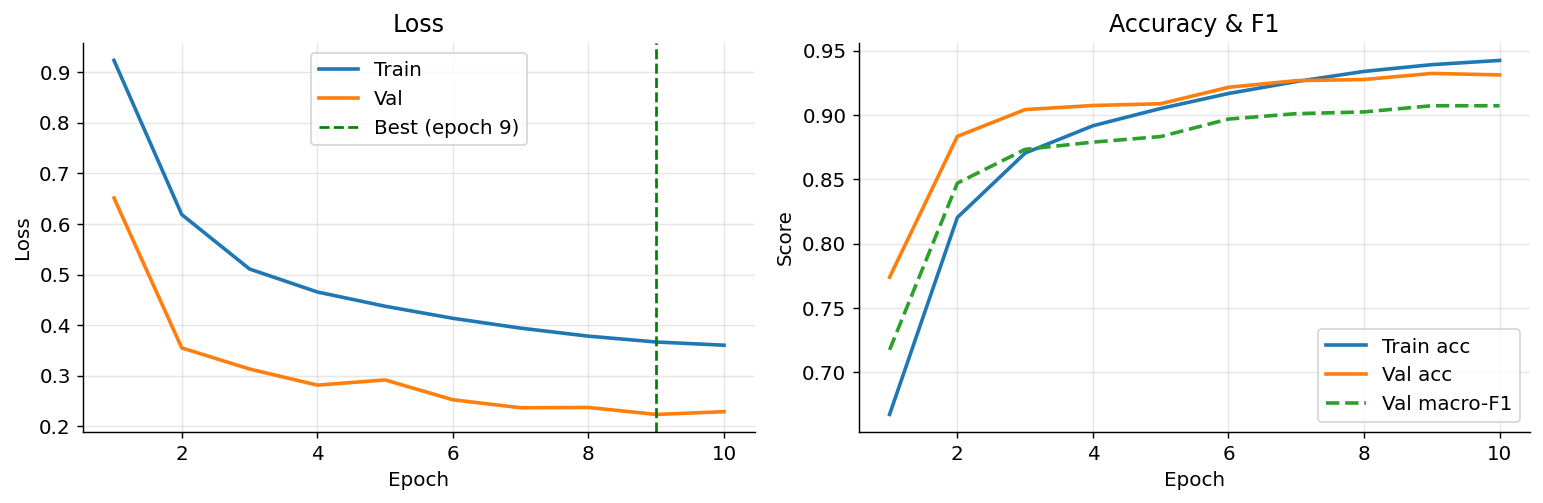

In [135]:
hist = pd.read_csv(HISTORY)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
best_epoch = hist.loc[hist['validation_macro_f1'].idxmax(), 'epoch']

ax = axes[0]
ax.plot(hist['epoch'], hist['train_loss'],      lw=2, color='#1f77b4', label='Train')
ax.plot(hist['epoch'], hist['validation_loss'], lw=2, color='#ff7f0e', label='Val')
ax.axvline(best_epoch, color='green', ls='--', lw=1.5, label=f'Best (epoch {best_epoch})')
ax.set_xlabel('Epoch'); ax.set_ylabel('Loss')
ax.set_title('Loss'); ax.legend()

ax = axes[1]
ax.plot(hist['epoch'], hist['train_accuracy'],      lw=2, color='#1f77b4', label='Train acc')
ax.plot(hist['epoch'], hist['validation_accuracy'], lw=2, color='#ff7f0e', label='Val acc')
ax.plot(hist['epoch'], hist['validation_macro_f1'], lw=2, color='#2ca02c', ls='--', label='Val macro-F1')
ax.set_xlabel('Epoch'); ax.set_ylabel('Score')
ax.set_title('Accuracy & F1'); ax.legend()

plt.tight_layout()
plt.savefig('fig_training_curve.png', bbox_inches='tight')
plt.show()

**Explanation:** Train/val loss and accuracy over training epochs.

**Finding:** Training looks healthy (converges without an obvious late crash). The Anopheles test errors are unlikely to be from a broken training run; they are a hard class-boundary problem.


## 10. Summary of findings

| Finding | Evidence | Implication |
|---|---|---|
| *An. arabiensis* has the lowest F1 (0.782) | Per-class metrics | Further investigation needed |
| *An. gambiae* ↔ *An. arabiensis* confusion dominates errors | Confusion matrix | Species boundary is acoustically weak |
| Confusion is **asymmetric**: 16.7% of *An. arabiensis* → *An. gambiae*, only 6.3% reverse | Confusion matrix | *An. arabiensis* harder to separate |
| Errors are **high-confidence** (model is overconfident) | Confidence CDF | Dangerous in deployment – wrong with certainty |
| Original `spectral_peak_hz` is unreliable (~6 Hz for most Anopheles) | Compare to `f0_hz` | Frequency analyses must use band-limited `f0_hz` |
| With `f0_hz` on **all** clips, Anopheles peaks still overlap (~550–900 Hz) | Frequency histograms | Sibling species remain hard to separate by peak alone |
| H2 (atypical f0 → error) is **mixed** on full data | H2 lift table | Strong for albopictus; weak/reversed for arabiensis |

### Open questions for Phase II
- Does CBAM attention focus on the **same harmonic lines** for both Anopheles in the overlap zone?
- Are confused samples' internal feature representations actually the same cluster in the penultimate layer?
- Could training with a **paired contrastive loss** on these two species improve separation?
- H6 (partial events) / H7 (background) given H2 is not the main arabiensis driver?


## 11. Deeper analysis – what drives the Anopheles confusion?

The asymmetry (16.7% arabiensis→gambiae vs 6.3% gambiae→arabiensis) and the overconfidence on wrong predictions demand a deeper look. Four complementary angles:

| # | Question | Method |
|---|---|---|
| 11a | Do confused samples form a sub-cluster in probability space? | PCA on 6 prob columns |
| 11b | Are errors concentrated in specific recording sessions? | Per-session error rates |
| 11c | Is the model making *close calls* or *confident mistakes*? | prob_gambiae vs prob_arabiensis scatter |
| 11d | Is the error distribution uniform across sessions (Gini / Lorenz)? | Session uniformity analysis |

### 11a. Sub-clusters in probability space (PCA on the 6 probability outputs)

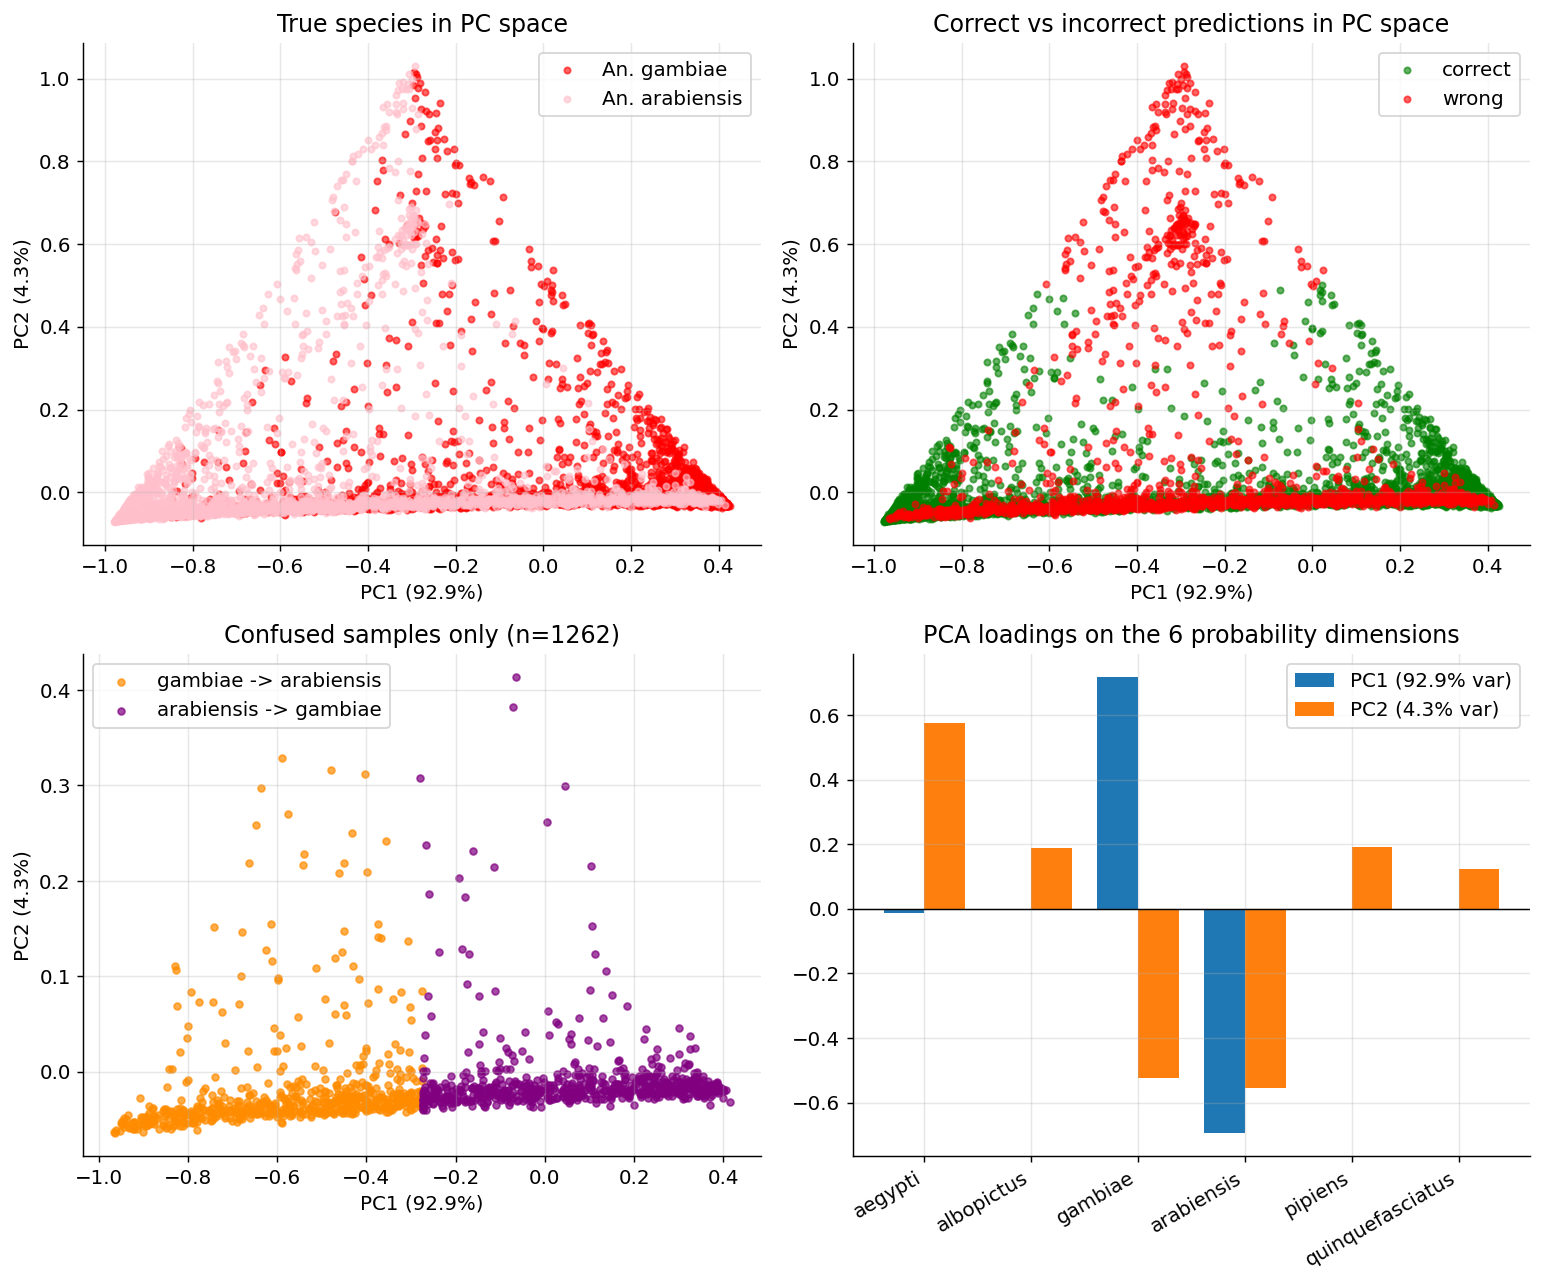

Anopheles test samples: 13754
Confused: 1262 (9.2%) - gambiae->arabiensis: 619, arabiensis->gambiae: 643
Centroid distance (confused vs correct, PC space): 0.281
Confused samples closer to the confused centroid than the correct centroid: 61.9%
Verdict: confused samples partially separate from correct samples


In [136]:
an = df[df['true_species'].isin(['An. gambiae', 'An. arabiensis'])].copy()
prob_cols = ['prob_aegypti', 'prob_albopictus', 'prob_gambiae', 'prob_arabiensis', 'prob_pipiens', 'prob_quinquefasciatus']
X = an[prob_cols].to_numpy(dtype=float)
Xc = X - X.mean(axis=0)
U, S, Vt = np.linalg.svd(Xc, full_matrices=False)
scores = Xc @ Vt[:2].T
loadings = Vt[:2]
var_ratio = S**2 / np.sum(S**2)
an['pc1'], an['pc2'] = scores[:, 0], scores[:, 1]
an['correct'] = an['correct'].astype(bool)

to_ga = (an['true_species'] == 'An. gambiae') & (an['predicted_species'] == 'An. arabiensis')
to_ar = (an['true_species'] == 'An. arabiensis') & (an['predicted_species'] == 'An. gambiae')
confused = an[to_ga | to_ar]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
ax1, ax2, ax3, ax4 = axes.ravel()

for sp, c in [('An. gambiae', 'red'), ('An. arabiensis', 'pink')]:
    m = an['true_species'] == sp
    ax1.scatter(an.loc[m, 'pc1'], an.loc[m, 'pc2'], s=12, alpha=0.6, c=c, label=sp)
ax1.set_title('True species in PC space')
ax1.set_xlabel(f'PC1 ({var_ratio[0]:.1%})')
ax1.set_ylabel(f'PC2 ({var_ratio[1]:.1%})')
ax1.legend()

for flag, c, lab in [(True, 'green', 'correct'), (False, 'red', 'wrong')]:
    m = an['correct'] == flag
    ax2.scatter(an.loc[m, 'pc1'], an.loc[m, 'pc2'], s=12, alpha=0.6, c=c, label=lab)
ax2.set_title('Correct vs incorrect predictions in PC space')
ax2.set_xlabel(f'PC1 ({var_ratio[0]:.1%})')
ax2.set_ylabel(f'PC2 ({var_ratio[1]:.1%})')
ax2.legend()

for m, c, lab in [(to_ga[to_ga | to_ar], 'darkorange', 'gambiae -> arabiensis'),
                  (to_ar[to_ga | to_ar], 'purple', 'arabiensis -> gambiae')]:
    ax3.scatter(confused.loc[m, 'pc1'], confused.loc[m, 'pc2'], s=14, alpha=0.7, c=c, label=lab)
ax3.set_title(f'Confused samples only (n={len(confused)})')
ax3.set_xlabel(f'PC1 ({var_ratio[0]:.1%})')
ax3.set_ylabel(f'PC2 ({var_ratio[1]:.1%})')
ax3.legend()

x = np.arange(len(prob_cols))
w = 0.38
short = [c.replace('prob_', '') for c in prob_cols]
ax4.bar(x - w / 2, loadings[0], w, label=f'PC1 ({var_ratio[0]:.1%} var)')
ax4.bar(x + w / 2, loadings[1], w, label=f'PC2 ({var_ratio[1]:.1%} var)')
ax4.axhline(0, color='black', lw=0.8)
ax4.set_xticks(x)
ax4.set_xticklabels(short, rotation=30, ha='right')
ax4.set_title('PCA loadings on the 6 probability dimensions')
ax4.legend()

plt.tight_layout()
plt.savefig('fig_subcluster_probspace.png', dpi=150, bbox_inches='tight')
plt.show()

n_conf = len(confused)
n_ga, n_ar = int(to_ga.sum()), int(to_ar.sum())
print(f"Anopheles test samples: {len(an)}")
print(f"Confused: {n_conf} ({n_conf / len(an):.1%}) - gambiae->arabiensis: {n_ga}, arabiensis->gambiae: {n_ar}")

P = an[['pc1', 'pc2']].to_numpy()
conf_mask = (to_ga | to_ar).to_numpy()
ok_mask = (an['correct']).to_numpy()
c_conf = P[conf_mask].mean(axis=0)
c_ok = P[ok_mask].mean(axis=0)
d_conf = np.linalg.norm(P[conf_mask] - c_conf, axis=1)
d_ok = np.linalg.norm(P[conf_mask] - c_ok, axis=1)
frac_closer = np.mean(d_conf < d_ok)
print(f"Centroid distance (confused vs correct, PC space): {np.linalg.norm(c_conf - c_ok):.3f}")
print(f"Confused samples closer to the confused centroid than the correct centroid: {frac_closer:.1%}")
if frac_closer > 0.8:
    print("Verdict: confused samples form a distinct sub-cluster")
elif frac_closer < 0.6:
    print("Verdict: confused samples are mixed with correct samples")
else:
    print("Verdict: confused samples partially separate from correct samples")

**Explanation:** PCA on the 6 softmax probabilities for Anopheles; compare correct vs mutually confused clips.

**Finding:** Confused samples partially separate (≈62% closer to the confused centroid; centroid distance ≈0.28). Not random, but not a clean isolated cluster either.


### 11b. Session-level error clustering – is confusion driven by specific recording sessions?

Sessions (n>=10): arabiensis=192, gambiae=493, shared D_* ids=0


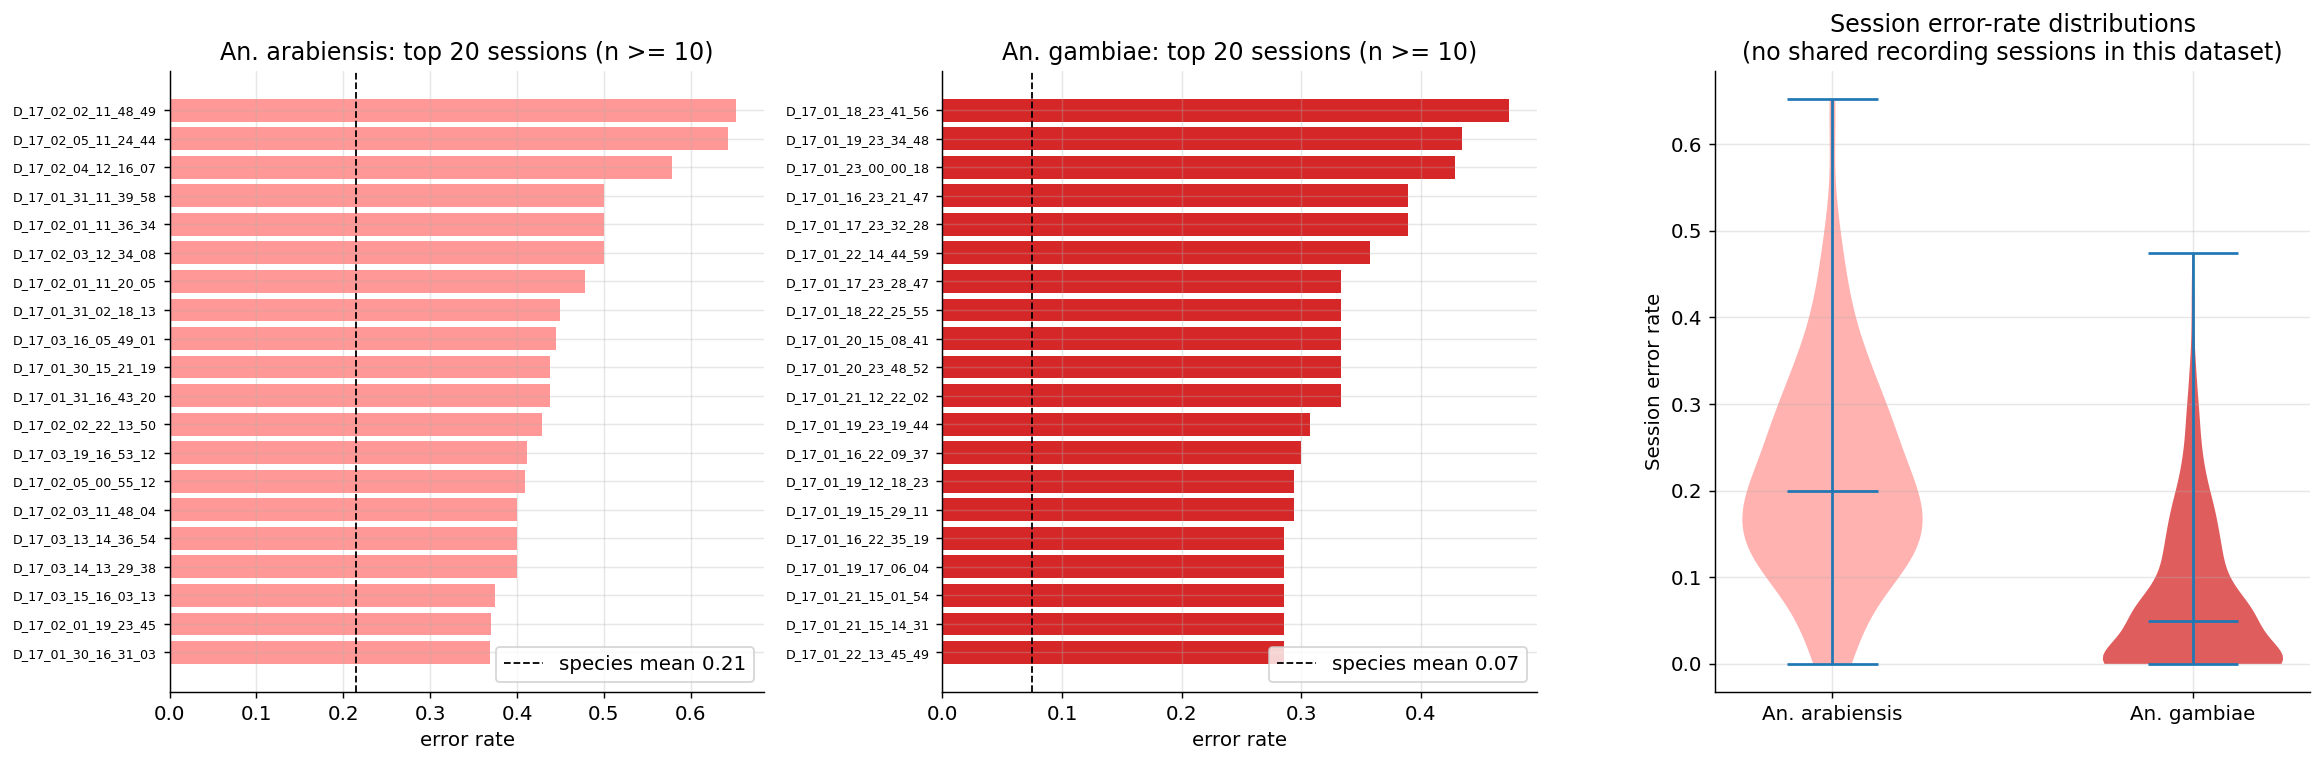

An. arabiensis: top 10% of sessions (20 of 194) hold 23.3% of all errors
An. gambiae: top 10% of sessions (50 of 495) hold 37.0% of all errors


In [137]:
MIN_N, TOP_N = 10, 20
ARAB, GAMB = 'An. arabiensis', 'An. gambiae'

def session_table(sp):
    d = df[df['true_species'] == sp]
    t = d.groupby('session')['correct'].agg(n='size', n_correct='sum')
    t['errors'] = t['n'] - t['n_correct']
    t['error_rate'] = t['errors'] / t['n']
    return t, 1 - d['correct'].astype(bool).mean()

arab_all, arab_mean = session_table(ARAB)
gamb_all, gamb_mean = session_table(GAMB)
arab = arab_all[arab_all['n'] >= MIN_N]
gamb = gamb_all[gamb_all['n'] >= MIN_N]

# Species never share D_* recording folders in this dataset – compare distributions, not paired sessions.
shared = set(arab.index) & set(gamb.index)
print(f'Sessions (n>={MIN_N}): arabiensis={len(arab)}, gambiae={len(gamb)}, shared D_* ids={len(shared)}')

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, t, sp, mean in [(axes[0], arab, ARAB, arab_mean), (axes[1], gamb, GAMB, gamb_mean)]:
    top = t.nlargest(TOP_N, 'error_rate').iloc[::-1]
    ax.barh(range(len(top)), top['error_rate'], color=SPECIES_COLORS[sp])
    ax.set_yticks(range(len(top)))
    ax.set_yticklabels(top.index.astype(str), fontsize=7)
    ax.axvline(mean, color='k', ls='--', lw=1, label=f'species mean {mean:.2f}')
    ax.set(title=f'{sp}: top {TOP_N} sessions (n >= {MIN_N})', xlabel='error rate')
    ax.legend(loc='lower right')

ax = axes[2]
parts = ax.violinplot([arab['error_rate'].to_numpy(), gamb['error_rate'].to_numpy()],
                      showmedians=True, showextrema=True)
for body, sp in zip(parts['bodies'], [ARAB, GAMB]):
    body.set_facecolor(SPECIES_COLORS[sp])
    body.set_alpha(0.75)
ax.set_xticks([1, 2])
ax.set_xticklabels([ARAB, GAMB])
ax.set_ylabel('Session error rate')
ax.set_title('Session error-rate distributions\n(no shared recording sessions in this dataset)')

plt.tight_layout()
plt.savefig('fig_session_errors.png', dpi=150, bbox_inches='tight')
plt.show()

def top_decile_share(sp):
    t, _ = session_table(sp)
    k = max(1, int(np.ceil(0.10 * len(t))))
    e = t['errors'].sort_values(ascending=False)
    return k, len(t), e.iloc[:k].sum() / max(e.sum(), 1)

for sp in [ARAB, GAMB]:
    k, n_sess, share = top_decile_share(sp)
    print(f'{sp}: top 10% of sessions ({k} of {n_sess}) hold {share:.1%} of all errors')


**Explanation:** Highest-error sessions per Anopheles species, plus session error-rate distributions. Session = `D_*` parent folder.

**Finding:** Top 10% of sessions hold ~23% (*arabiensis*) and ~37% (*gambiae*) of that species’ errors. The two species share **0** recording sessions, so confusion is not from mixed-species tapes.


### 11c. Probability scatter – close calls or confident mistakes?

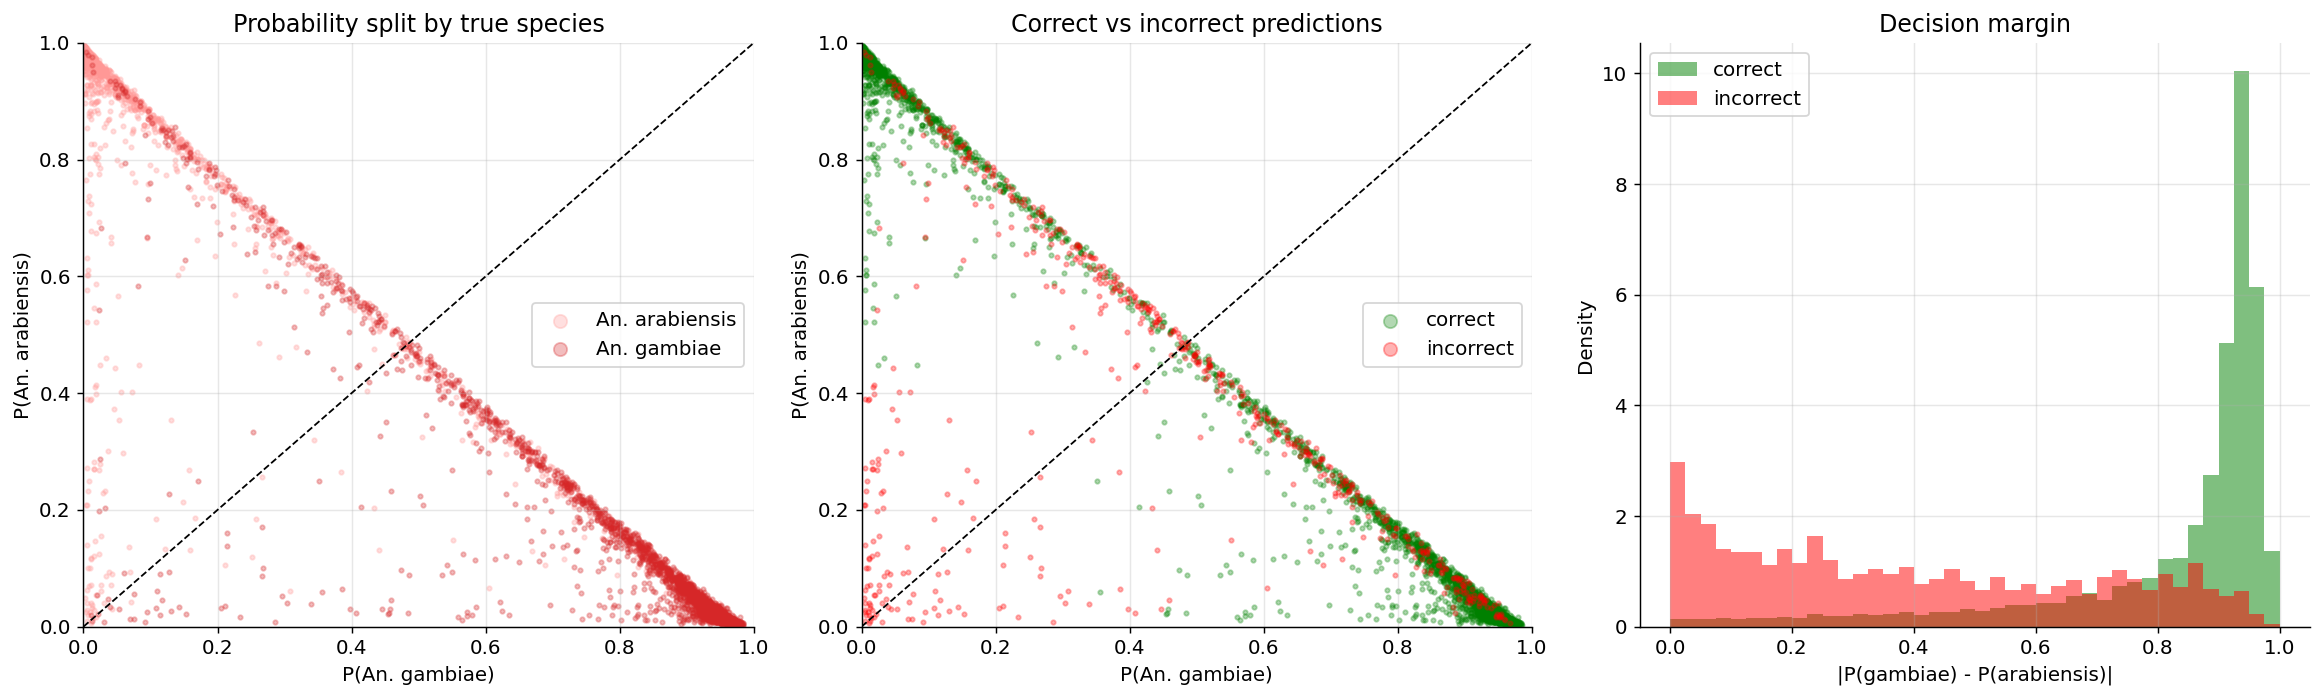

Median decision margin - correct: 0.916, incorrect: 0.340
Errors with margin > 0.3 (confidently wrong): 54.1% of 1569 errors


In [138]:
an = df[df['true_species'].str.startswith('An.')].copy()
an['correct'] = an['correct'].astype(bool)
an['margin'] = (an['prob_gambiae'] - an['prob_arabiensis']).abs()
samp = an.sample(n=min(5000, len(an)), random_state=42)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

ax = axes[0]
for sp, g in samp.groupby('true_species'):
    ax.scatter(g['prob_gambiae'], g['prob_arabiensis'], s=6, alpha=0.3,
               color=SPECIES_COLORS.get(sp, 'gray'), label=sp)
ax.plot([0, 1], [0, 1], 'k--', lw=1)
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel='P(An. gambiae)', ylabel='P(An. arabiensis)',
       title='Probability split by true species')
ax.legend(markerscale=3)

ax = axes[1]
for ok, color, label in [(True, 'green', 'correct'), (False, 'red', 'incorrect')]:
    g = samp[samp['correct'] == ok]
    ax.scatter(g['prob_gambiae'], g['prob_arabiensis'], s=6, alpha=0.3, color=color, label=label)
ax.plot([0, 1], [0, 1], 'k--', lw=1)
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel='P(An. gambiae)', ylabel='P(An. arabiensis)',
       title='Correct vs incorrect predictions')
ax.legend(markerscale=3)

ax = axes[2]
bins = np.linspace(0, 1, 41)
ax.hist(an.loc[an['correct'], 'margin'], bins=bins, alpha=0.5, density=True, color='green', label='correct')
ax.hist(an.loc[~an['correct'], 'margin'], bins=bins, alpha=0.5, density=True, color='red', label='incorrect')
ax.set(xlabel='|P(gambiae) - P(arabiensis)|', ylabel='Density', title='Decision margin')
ax.legend()

plt.tight_layout()
plt.savefig('fig_prob_scatter.png', dpi=150, bbox_inches='tight')
plt.show()

correct_m = an.loc[an['correct'], 'margin']
wrong_m = an.loc[~an['correct'], 'margin']
print(f"Median decision margin - correct: {correct_m.median():.3f}, incorrect: {wrong_m.median():.3f}")
print(f"Errors with margin > 0.3 (confidently wrong): {(wrong_m > 0.3).mean():.1%} of {len(wrong_m)} errors")

**Explanation:** Scatter of P(*gambiae*) vs P(*arabiensis*) for Anopheles, plus decision-margin histograms for correct vs incorrect.

**Finding:** Many errors are not razor-edge ties: median margin is 0.92 (correct) vs 0.34 (incorrect), but **>50%** of errors still have margin >0.3 — confidently wrong. Confidence/margin alone won’t catch them all.


### 11d. Session uniformity – are errors spread evenly or concentrated in a few sessions?

Sessions per species:
true_species
An. arabiensis    194
An. gambiae       495
Shared D_* session ids: 0


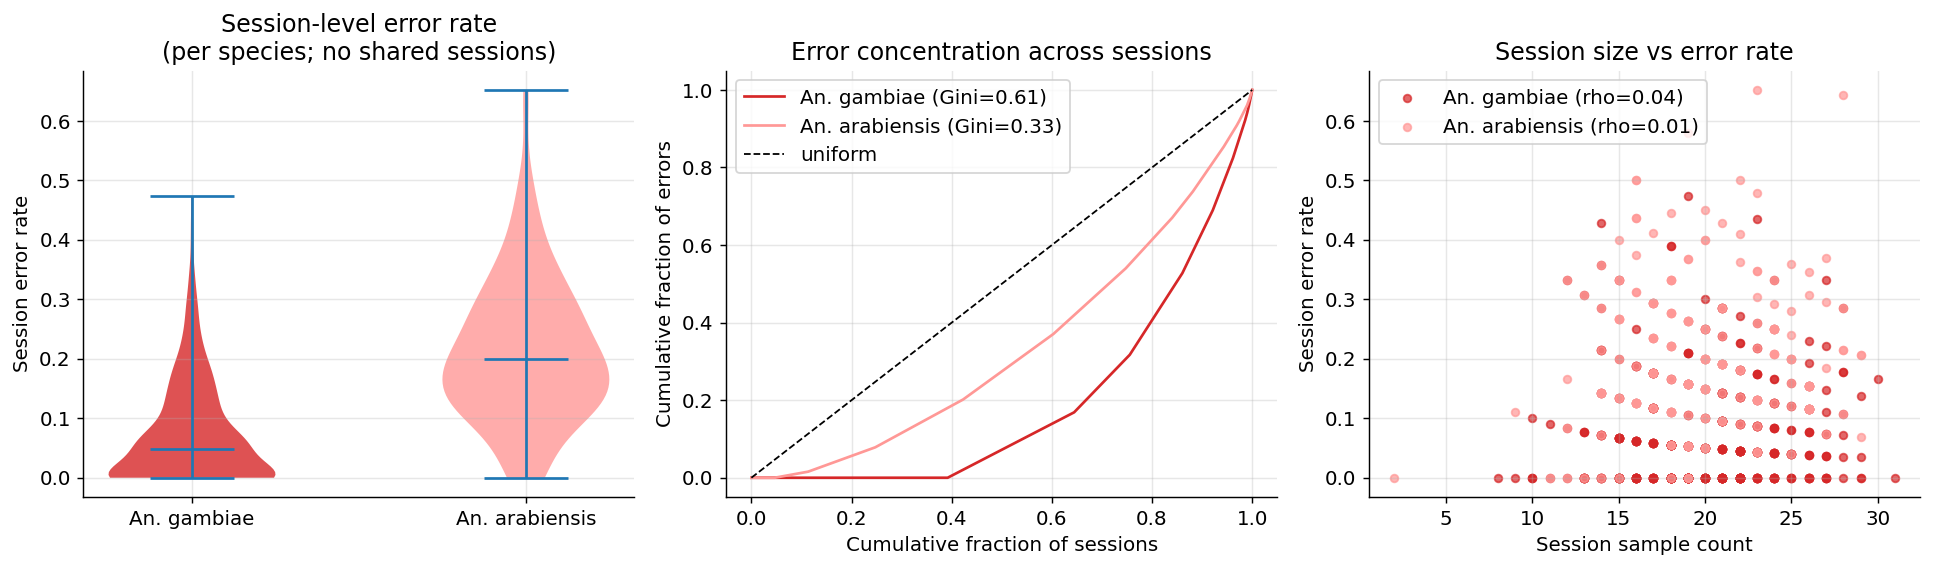

An. gambiae: sessions=495, Gini=0.610, Spearman(size, error rate)=0.039
An. arabiensis: sessions=194, Gini=0.330, Spearman(size, error rate)=0.014


In [139]:
SP = ['An. gambiae', 'An. arabiensis']
anop = df[df['true_species'].isin(SP)].copy()
anop['err'] = ~anop['correct'].astype(bool)

g_all = (anop.groupby(['session', 'true_species'])
             .agg(n=('err', 'size'), errors=('err', 'sum'))
             .reset_index())
g_all['err_rate'] = g_all['errors'] / g_all['n']

print('Sessions per species:')
print(g_all.groupby('true_species')['session'].nunique().to_string())
print('Shared D_* session ids:',
      len(set(g_all.loc[g_all.true_species==SP[0],'session']) &
          set(g_all.loc[g_all.true_species==SP[1],'session'])))

def gini(counts):
    x = np.sort(np.asarray(counts, dtype=float))
    if x.sum() == 0 or len(x) == 0:
        return 0.0
    n = len(x)
    i = np.arange(1, n + 1)
    return float(2 * np.sum(i * x) / (n * np.sum(x)) - (n + 1) / n)

lorenz, ginis, rho = {}, {}, {}
for sp in SP:
    sub = g_all[g_all['true_species'] == sp]
    e = np.sort(sub['errors'].to_numpy(dtype=float))
    total = e.sum()
    cs = np.concatenate([[0.0], np.cumsum(e) / total]) if total > 0 else np.linspace(0, 1, len(e) + 1)
    lorenz[sp] = (np.arange(len(cs)) / max(len(e), 1), cs)
    ginis[sp] = gini(e)
    rho[sp] = sub['n'].corr(sub['err_rate'], method='spearman')

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# Panel 1: each species' own session error rates (they never co-occur in one D_* folder)
ax = axes[0]
data = [g_all.loc[g_all['true_species'] == sp, 'err_rate'].to_numpy() for sp in SP]
parts = ax.violinplot(data, showmedians=True, showextrema=True)
for body, sp in zip(parts['bodies'], SP):
    body.set_facecolor(SPECIES_COLORS[sp])
    body.set_alpha(0.8)
ax.set_xticks([1, 2])
ax.set_xticklabels(SP)
ax.set_ylabel('Session error rate')
ax.set_title('Session-level error rate\n(per species; no shared sessions)')

ax = axes[1]
for sp in SP:
    x, y = lorenz[sp]
    ax.plot(x, y, color=SPECIES_COLORS[sp], label=f'{sp} (Gini={ginis[sp]:.2f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='uniform')
ax.set(xlabel='Cumulative fraction of sessions', ylabel='Cumulative fraction of errors',
       title='Error concentration across sessions')
ax.legend()

ax = axes[2]
for sp in SP:
    sub = g_all[g_all['true_species'] == sp]
    ax.scatter(sub['n'], sub['err_rate'], s=18, alpha=0.7, color=SPECIES_COLORS[sp],
               label=f'{sp} (rho={rho[sp]:.2f})')
ax.set(xlabel='Session sample count', ylabel='Session error rate', title='Session size vs error rate')
ax.legend()

fig.tight_layout()
fig.savefig('fig_session_uniformity.png', dpi=150, bbox_inches='tight')
plt.show()

for sp in SP:
    print(f'{sp}: sessions={len(g_all[g_all["true_species"] == sp])}, '
          f'Gini={ginis[sp]:.3f}, Spearman(size, error rate)={rho[sp]:.3f}')


**Explanation:** Per-species session error violins, Lorenz curves (error concentration), and size vs error. Species never share `D_*` sessions.

**Finding:** Errors are uneven across sessions — Gini ≈0.61 (*gambiae*) vs ≈0.33 (*arabiensis*). Top 10% of sessions hold a large share of errors. Session concentration is real; co-recording cannot explain the sibling swap.


### 11e. Session size vs error rate — all 6 species individually

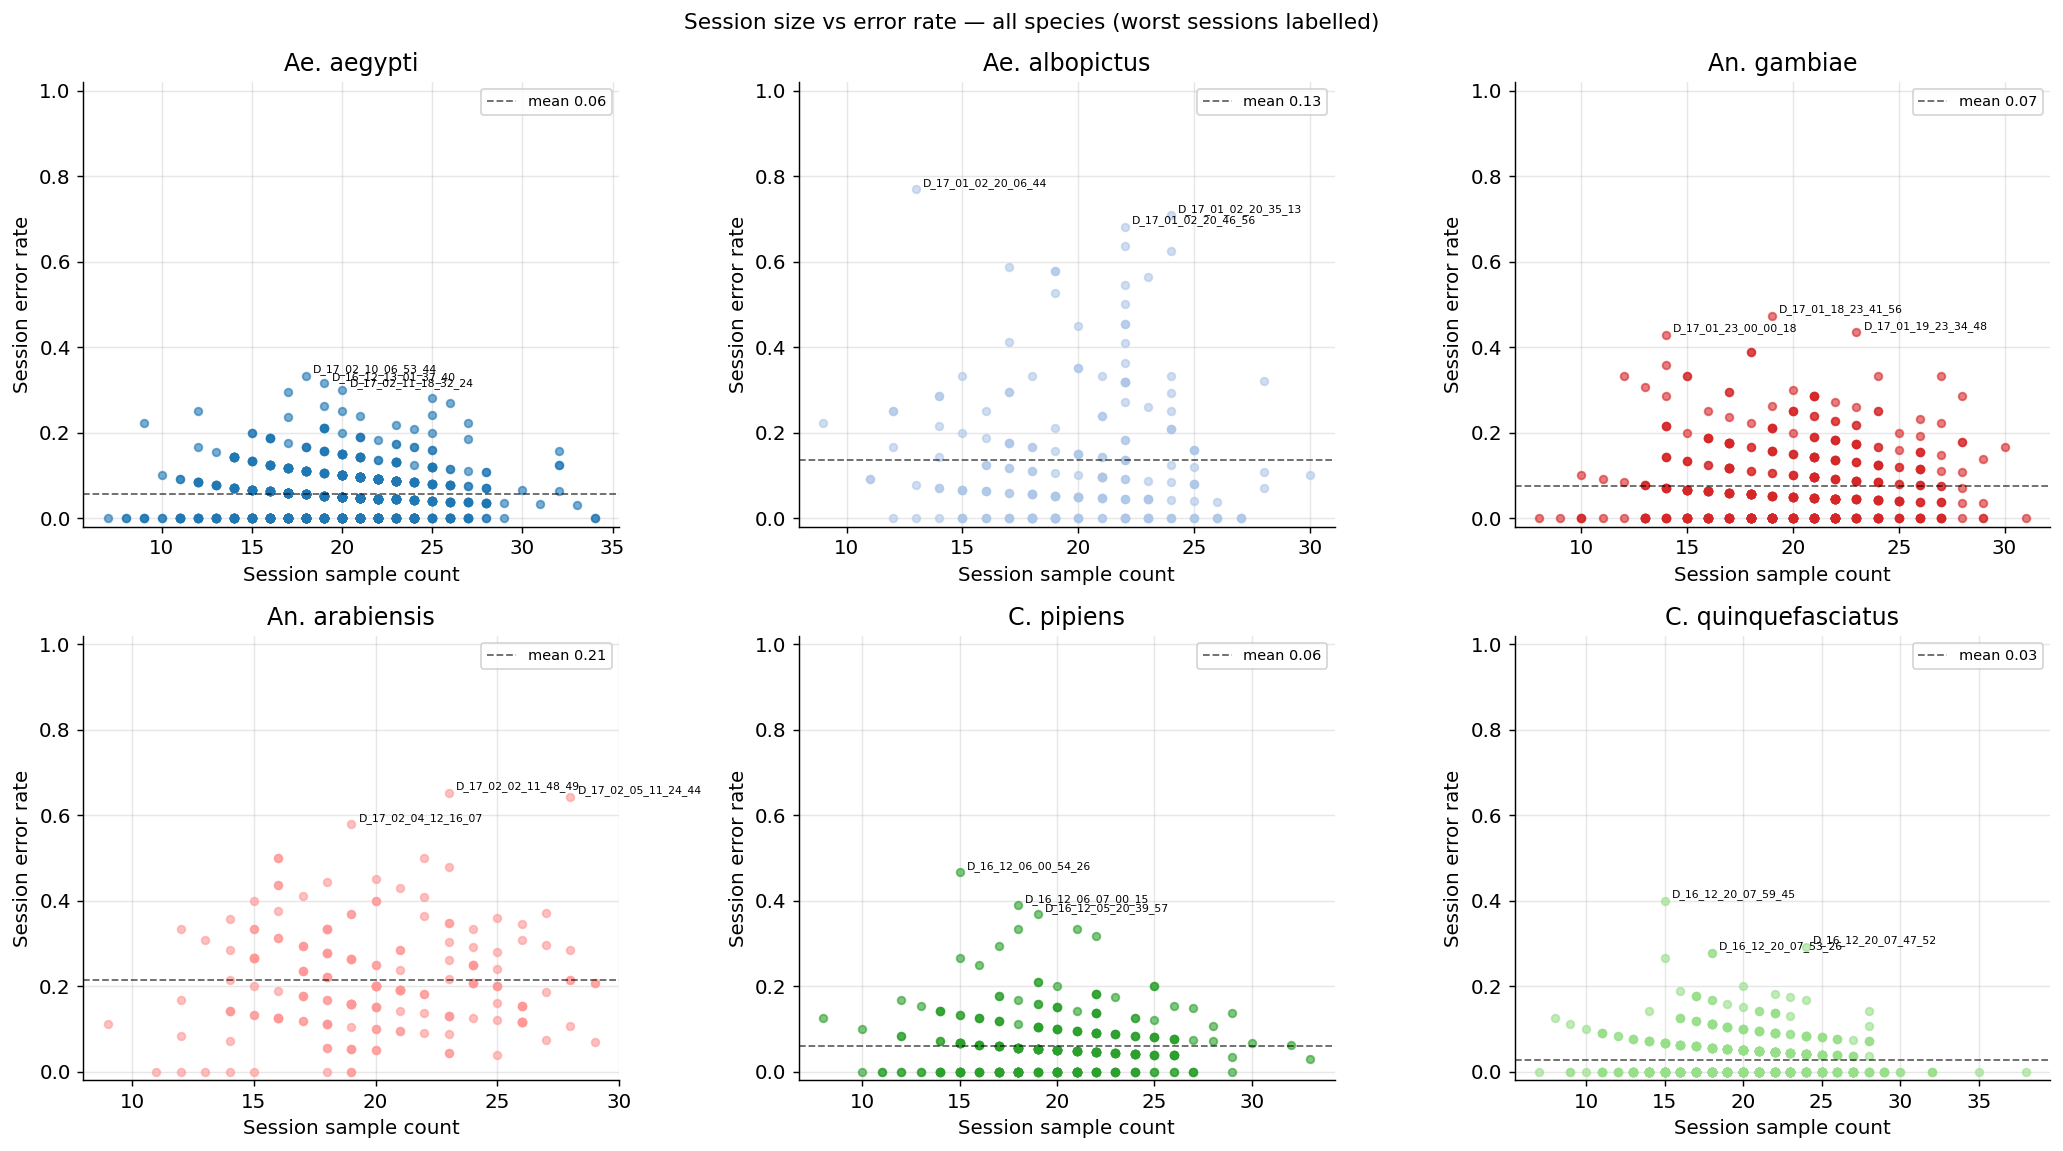

In [140]:
MIN_SESS = 5   # min samples in a session to plot it
TOP_LABEL = 3  # label the N worst sessions per species

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, sp in zip(axes.flatten(), SPECIES_ORDER):
    sub = df[df['true_species'] == sp]
    sess = sub.groupby('session')['correct'].agg(n='size', n_correct='sum')
    sess['errors']     = sess['n'] - sess['n_correct']
    sess['error_rate'] = sess['errors'] / sess['n']
    sess = sess[sess['n'] >= MIN_SESS]

    ax.scatter(sess['n'], sess['error_rate'], s=18, alpha=0.6,
               color=SPECIES_COLORS[sp], zorder=2)

    # label the worst outliers
    worst = sess.nlargest(TOP_LABEL, 'error_rate')
    for sid, row in worst.iterrows():
        ax.annotate(sid, (row['n'], row['error_rate']),
                    textcoords='offset points', xytext=(4, 2),
                    fontsize=6, color='black')

    sp_mean = 1 - sub['correct'].astype(bool).mean()
    ax.axhline(sp_mean, color='black', ls='--', lw=1, alpha=0.6,
               label=f'mean {sp_mean:.2f}')
    ax.set(xlabel='Session sample count', ylabel='Session error rate', title=sp)
    ax.legend(fontsize=8)
    ax.set_ylim(-0.02, 1.02)

plt.suptitle('Session size vs error rate — all species (worst sessions labelled)', fontsize=12)
plt.tight_layout()
plt.savefig('fig_session_size_vs_error_all.png', dpi=150, bbox_inches='tight')
plt.show()

**Explanation:** Session size vs session error rate, one panel/colour per species.

**Finding:** Little evidence that small sessions alone cause high error (weak size–error link). Bad sessions exist at many sizes — quality/batch effects, not just low *n*.


### 11f. Outlier session metadata — what is different about the worst sessions?

Session IDs encode recording date and time: `D_YY_MM_DD_HH_MM_SS`.
We parse this to check whether bad sessions cluster on specific dates, times of day, or months.

=== Top 10 worst An. arabiensis sessions ===
            session  n  errors  error_rate  month  day  hour
D_17_02_02_11_48_49 23      15    0.652174      2    2    11
D_17_02_05_11_24_44 28      18    0.642857      2    5    11
D_17_02_04_12_16_07 19      11    0.578947      2    4    12
D_17_02_01_11_36_34 16       8    0.500000      2    1    11
D_17_01_31_11_39_58 16       8    0.500000      1   31    11
D_17_02_03_12_34_08 22      11    0.500000      2    3    12
D_17_02_01_11_20_05 23      11    0.478261      2    1    11
D_17_01_31_02_18_13 20       9    0.450000      1   31     2
D_17_03_16_05_49_01 18       8    0.444444      3   16     5
D_17_01_30_15_21_19 16       7    0.437500      1   30    15

=== Bottom 10 (best) An. arabiensis sessions (n>=10) ===
            session  n  errors  error_rate  month  day  hour
D_17_02_02_01_41_09 11       0    0.000000      2    2     1
D_17_01_31_23_45_52 13       0    0.000000      1   31    23
D_17_02_04_23_30_21 18       0    0.000000 

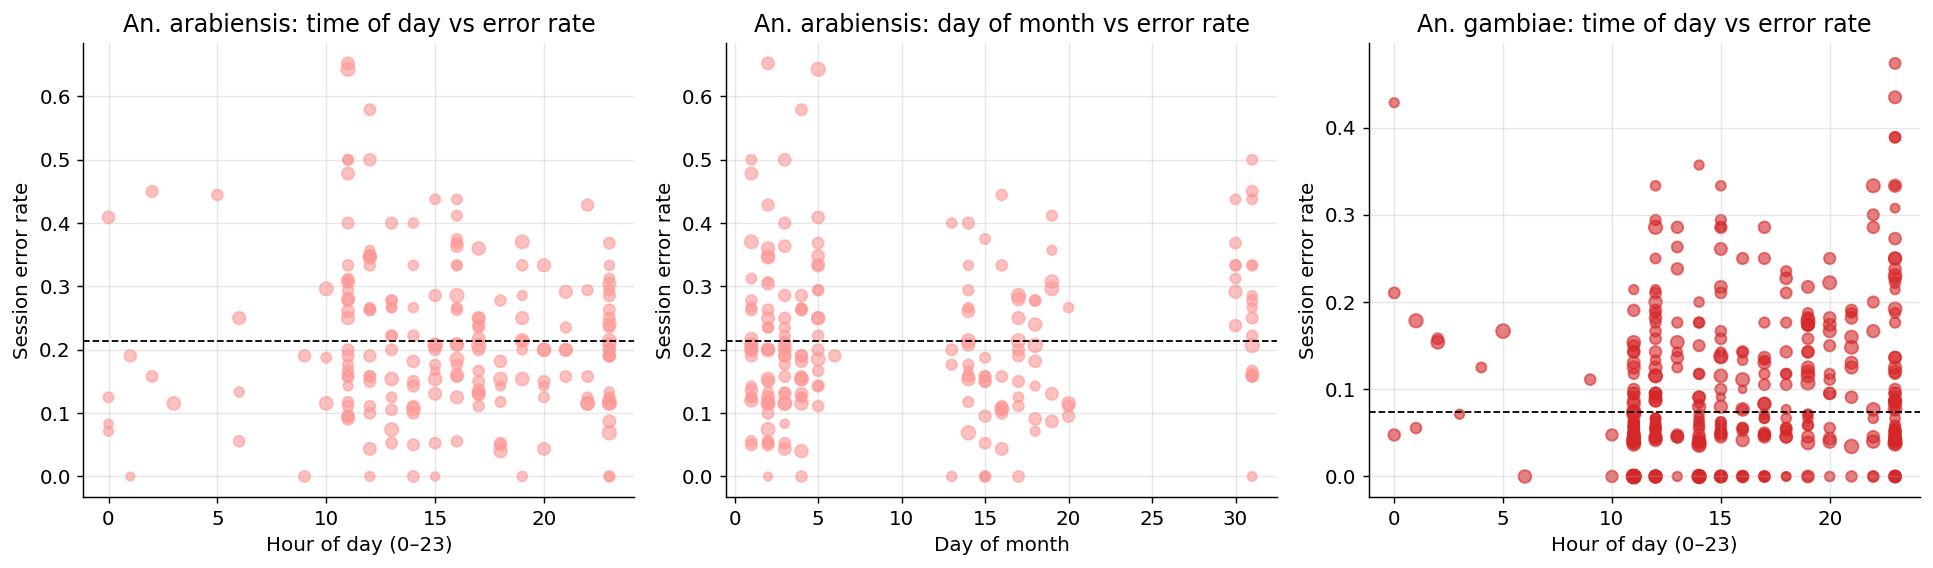


An. arabiensis sessions by month:
        mean  count
month              
1      0.284     23
2      0.216    106
3      0.184     64

An. gambiae sessions by month:
        mean  count
month              
1      0.075    495


In [141]:
import re

def parse_session(sid):
    # Format: D_YY_MM_DD_HH_MM_SS  e.g. D_17_02_02_11_48_49
    m = re.match(r'D_(\d+)_(\d+)_(\d+)_(\d+)_(\d+)_(\d+)', str(sid))
    if not m:
        return {}
    yy, mo, dd, hh, mi, ss = [int(x) for x in m.groups()]
    return {'year': 2000 + yy, 'month': mo, 'day': dd,
            'hour': hh, 'minute': mi, 'second': ss,
            'time_of_day': hh + mi / 60}

# Build a session-level table for all species
rows = []
for sp in SPECIES_ORDER:
    sub = df[df['true_species'] == sp]
    sess = sub.groupby('session')['correct'].agg(n='size', n_correct='sum').reset_index()
    sess['errors']     = sess['n'] - sess['n_correct']
    sess['error_rate'] = sess['errors'] / sess['n']
    sess['species']    = sp
    rows.append(sess)

sess_all = pd.concat(rows, ignore_index=True)
meta_df = pd.DataFrame([parse_session(s) for s in sess_all['session']])
sess_all = pd.concat([sess_all.reset_index(drop=True), meta_df], axis=1)

# ── Focus: worst arabiensis sessions ─────────────────────────────────────────
ara_sess = sess_all[(sess_all['species'] == 'An. arabiensis') & (sess_all['n'] >= 5)].copy()
ara_sess = ara_sess.sort_values('error_rate', ascending=False)

print('=== Top 10 worst An. arabiensis sessions ===')
print(ara_sess.head(10)[['session','n','errors','error_rate','month','day','hour']].to_string(index=False))

print('\n=== Bottom 10 (best) An. arabiensis sessions (n>=10) ===')
ara_good = ara_sess[ara_sess['n'] >= 10].sort_values('error_rate').head(10)
print(ara_good[['session','n','errors','error_rate','month','day','hour']].to_string(index=False))

# ── Compare metadata: top-25% worst vs bottom-25% best sessions (n>=10) ─────
ara_big = ara_sess[ara_sess['n'] >= 10].copy()
q75 = ara_big['error_rate'].quantile(0.75)
q25 = ara_big['error_rate'].quantile(0.25)
bad  = ara_big[ara_big['error_rate'] >= q75]
good = ara_big[ara_big['error_rate'] <= q25]

print(f'\n--- Worst quartile (error_rate >= {q75:.2f}, n={len(bad)}) ---')
print(bad[['month','day','hour']].describe().round(1))
print(f'\n--- Best quartile (error_rate <= {q25:.2f}, n={len(good)}) ---')
print(good[['month','day','hour']].describe().round(1))

# ── Visualise ─────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

ax = axes[0]
ax.scatter(ara_big['hour'], ara_big['error_rate'], s=ara_big['n']*2,
           alpha=0.6, color=SPECIES_COLORS['An. arabiensis'])
ax.set(xlabel='Hour of day (0–23)', ylabel='Session error rate',
       title='An. arabiensis: time of day vs error rate')
ax.axhline(ara_big['error_rate'].mean(), color='k', ls='--', lw=1)

ax = axes[1]
ax.scatter(ara_big['day'], ara_big['error_rate'], s=ara_big['n']*2,
           alpha=0.6, color=SPECIES_COLORS['An. arabiensis'])
ax.set(xlabel='Day of month', ylabel='Session error rate',
       title='An. arabiensis: day of month vs error rate')
ax.axhline(ara_big['error_rate'].mean(), color='k', ls='--', lw=1)

ax = axes[2]
# Same analysis for gambiae – do its outlier sessions share temporal patterns?
gam_sess = sess_all[(sess_all['species'] == 'An. gambiae') & (sess_all['n'] >= 5)].copy()
ax.scatter(gam_sess['hour'], gam_sess['error_rate'], s=gam_sess['n']*2,
           alpha=0.6, color=SPECIES_COLORS['An. gambiae'])
ax.set(xlabel='Hour of day (0–23)', ylabel='Session error rate',
       title='An. gambiae: time of day vs error rate')
ax.axhline(gam_sess['error_rate'].mean(), color='k', ls='--', lw=1)

plt.tight_layout()
plt.savefig('fig_session_metadata.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Quick summary of month distribution ──────────────────────────────────────
print('\nAn. arabiensis sessions by month:')
print(ara_sess.groupby('month')['error_rate'].agg(['mean','count']).round(3).to_string())
print('\nAn. gambiae sessions by month:')
print(gam_sess.groupby('month')['error_rate'].agg(['mean','count']).round(3).to_string())

**Explanation:** Worst vs best *An. arabiensis* sessions (error rate) with parsed date/hour from the `D_*` folder name.

**Finding:** Hard sessions reach ~45–65% error; easy ones can be 0%. They are specific recording runs, not a uniform failure. Points to session/batch quality as a Phase II lead.


### 11g. Statistical tests — is time of day a significant predictor of session error rate?

Kruskal-Wallis across time buckets: H=2.937, p=0.4014
(p < 0.05 → error rate differs significantly by time of day)

Mann-Whitney U (morning > other): U=3071.0, p=0.1385
  morning median error rate:  0.200  (n=35 sessions)
  non-morning median error rate: 0.200  (n=157 sessions)

Spearman correlation (hour vs error rate): rho=-0.053, p=0.4637
(negative rho → later in the day = fewer errors)

Per time-bucket summary (An. arabiensis, n>=10 sessions):
                    n  median   mean    std
time_bucket                                
night (0–6)        10   0.141  0.205  0.167
morning (6–12)     35   0.200  0.249  0.157
afternoon (12–18)  86   0.207  0.218  0.116
evening (18–24)    61   0.200  0.190  0.097


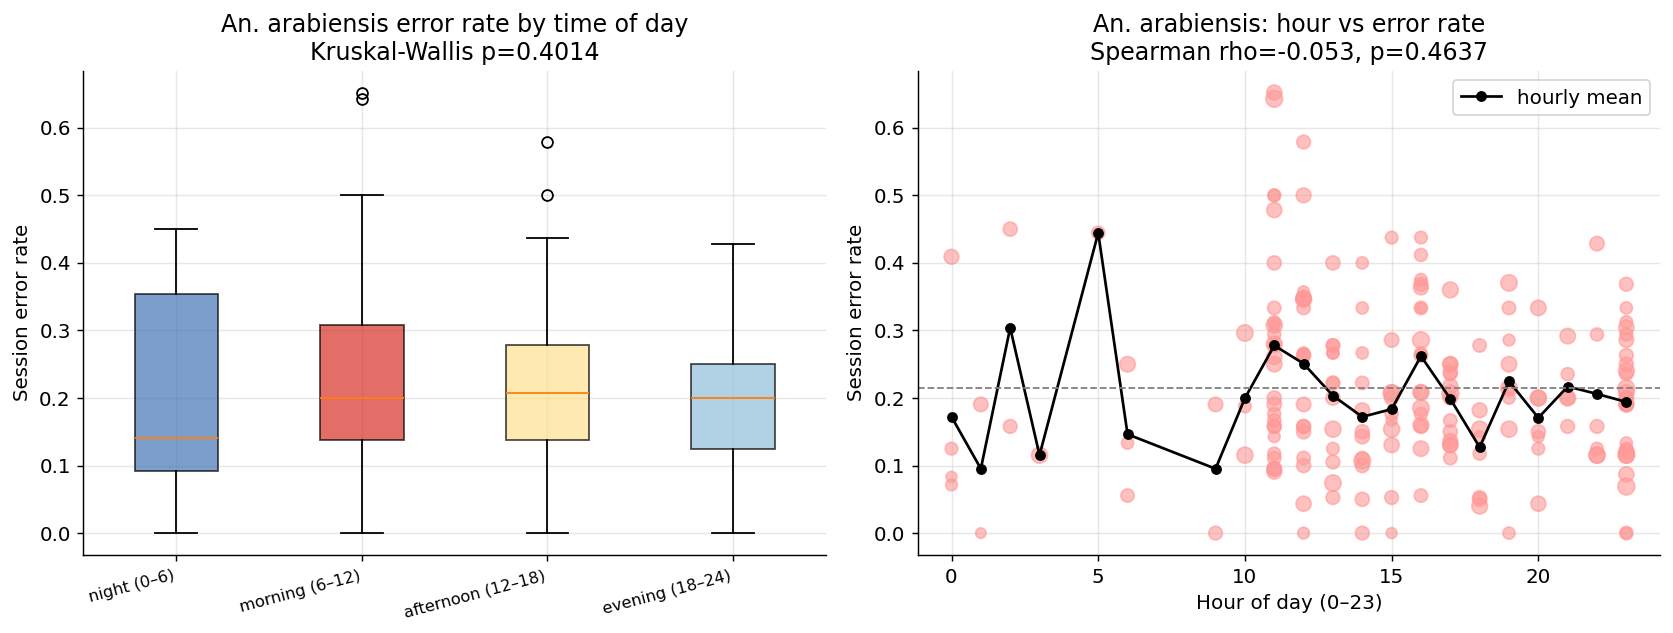

In [142]:
from scipy import stats

# ── Rebuild arabiensis session table with metadata (reuses parse_session) ─────
ara_big = sess_all[(sess_all['species'] == 'An. arabiensis') & (sess_all['n'] >= 10)].copy()

# Time-of-day buckets
def time_bucket(h):
    if  0 <= h <  6: return 'night (0–6)'
    if  6 <= h < 12: return 'morning (6–12)'
    if 12 <= h < 18: return 'afternoon (12–18)'
    return 'evening (18–24)'

ara_big['time_bucket'] = ara_big['hour'].apply(time_bucket)
bucket_order = ['night (0–6)', 'morning (6–12)', 'afternoon (12–18)', 'evening (18–24)']

# ── 1. Kruskal-Wallis across the 4 time buckets ───────────────────────────────
groups = [ara_big.loc[ara_big['time_bucket'] == b, 'error_rate'].to_numpy()
          for b in bucket_order]
groups_nonempty = [g for g in groups if len(g) >= 2]
kw_stat, kw_p = stats.kruskal(*groups_nonempty)
print(f'Kruskal-Wallis across time buckets: H={kw_stat:.3f}, p={kw_p:.4f}')
print('(p < 0.05 → error rate differs significantly by time of day)\n')

# ── 2. Mann-Whitney U: morning (6–12) vs all other times ─────────────────────
morning = ara_big.loc[ara_big['time_bucket'] == 'morning (6–12)', 'error_rate'].to_numpy()
other   = ara_big.loc[ara_big['time_bucket'] != 'morning (6–12)', 'error_rate'].to_numpy()
if len(morning) >= 2 and len(other) >= 2:
    mw_stat, mw_p = stats.mannwhitneyu(morning, other, alternative='greater')
    print(f'Mann-Whitney U (morning > other): U={mw_stat:.1f}, p={mw_p:.4f}')
    print(f'  morning median error rate:  {np.median(morning):.3f}  (n={len(morning)} sessions)')
    print(f'  non-morning median error rate: {np.median(other):.3f}  (n={len(other)} sessions)\n')

# ── 3. Spearman correlation: hour vs error rate ───────────────────────────────
sp_r, sp_p = stats.spearmanr(ara_big['hour'], ara_big['error_rate'])
print(f'Spearman correlation (hour vs error rate): rho={sp_r:.3f}, p={sp_p:.4f}')
print('(negative rho → later in the day = fewer errors)\n')

# ── 4. Per-bucket summary table ───────────────────────────────────────────────
summary = ara_big.groupby('time_bucket')['error_rate'].agg(
    n='count', median='median', mean='mean', std='std'
).reindex(bucket_order).round(3)
print('Per time-bucket summary (An. arabiensis, n>=10 sessions):')
print(summary.to_string())

# ── 5. Visualise ──────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ax = axes[0]
colors_bucket = ['#4575b4', '#d73027', '#fee090', '#91bfdb']
bp = ax.boxplot([g for g in groups], labels=bucket_order, patch_artist=True)
for patch, color in zip(bp['boxes'], colors_bucket):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
ax.set_ylabel('Session error rate')
ax.set_title(f'An. arabiensis error rate by time of day\nKruskal-Wallis p={kw_p:.4f}')
ax.set_xticklabels(bucket_order, rotation=15, ha='right', fontsize=9)

ax = axes[1]
ax.scatter(ara_big['hour'], ara_big['error_rate'],
           s=ara_big['n'] * 3, alpha=0.6,
           color=SPECIES_COLORS['An. arabiensis'])
# running mean per hour
hr_mean = ara_big.groupby('hour')['error_rate'].mean()
ax.plot(hr_mean.index, hr_mean.values, 'k-o', ms=5, lw=1.5, label='hourly mean')
ax.axhline(ara_big['error_rate'].mean(), color='gray', ls='--', lw=1)
ax.set(xlabel='Hour of day (0–23)', ylabel='Session error rate',
       title=f'An. arabiensis: hour vs error rate\nSpearman rho={sp_r:.3f}, p={sp_p:.4f}')
ax.legend()

plt.tight_layout()
plt.savefig('fig_session_time_stats.png', dpi=150, bbox_inches='tight')
plt.show()

**Explanation:** Kruskal–Wallis / Mann–Whitney / Spearman tests of *An. arabiensis* session error rate vs time-of-day buckets.

**Finding:** No significant time-of-day effect (Kruskal p≈0.40; morning vs other p≈0.14). Clock hour is not the driver — session identity matters more.


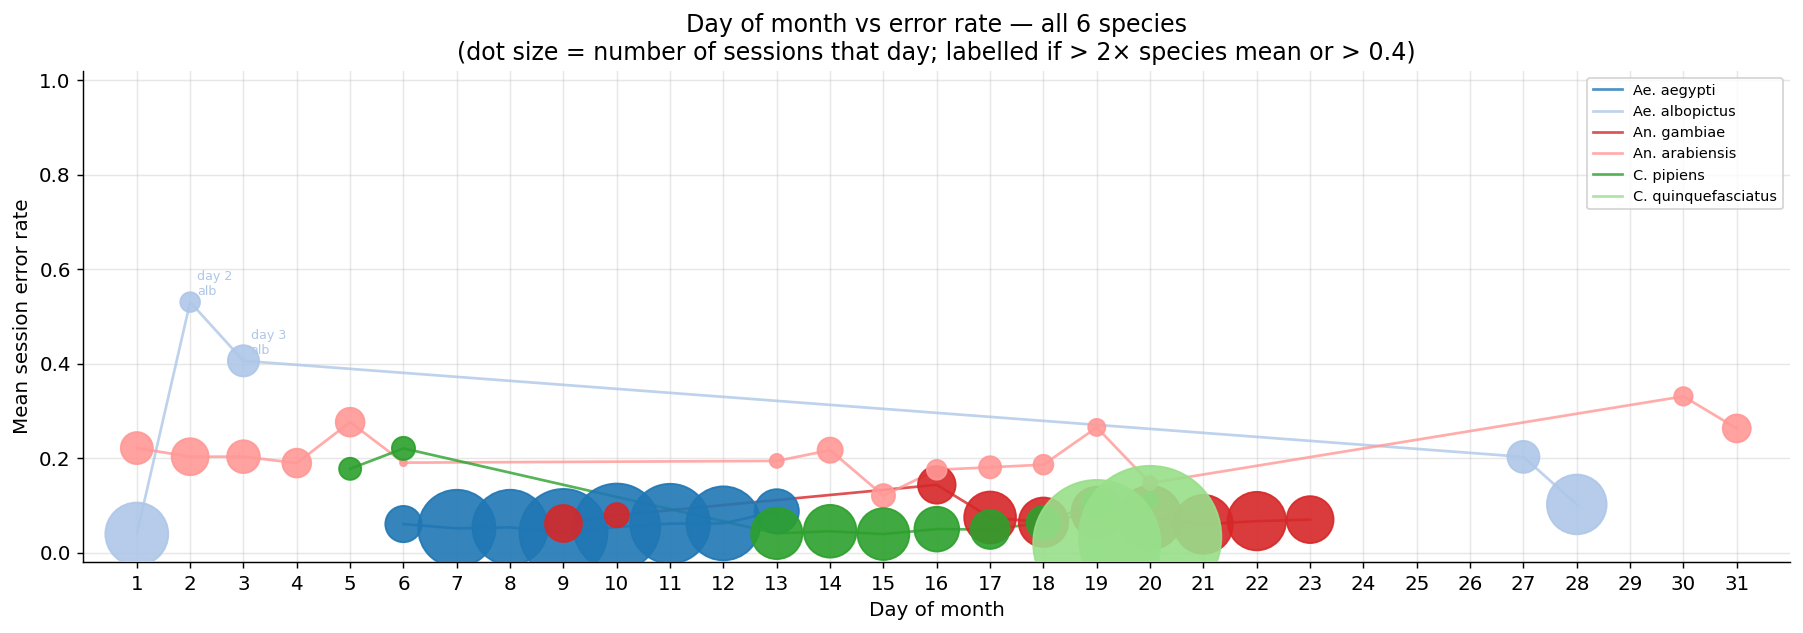

Days with mean error rate >= 0.4 for any species:
 day        species     mean  n
   2 Ae. albopictus 0.530055  8
   3 Ae. albopictus 0.405823 20


In [143]:
# Day of month vs error rate – all 6 species, one plot
# Aggregate to day level: mean error rate across all sessions that day, per species

day_sp = (sess_all[sess_all['n'] >= 5]
          .groupby(['species', 'day'])['error_rate']
          .agg(mean='mean', n='count')
          .reset_index())

# Overall species mean (horizontal reference)
sp_overall = {sp: 1 - df[df['true_species'] == sp]['correct'].astype(bool).mean()
              for sp in SPECIES_ORDER}

fig, ax = plt.subplots(figsize=(14, 5))

for sp in SPECIES_ORDER:
    sub = day_sp[day_sp['species'] == sp].sort_values('day')
    if sub.empty:
        continue
    color = SPECIES_COLORS[sp]
    # line connecting daily means
    ax.plot(sub['day'], sub['mean'], color=color, lw=1.5, alpha=0.8, label=sp)
    # dots sized by number of sessions that day
    ax.scatter(sub['day'], sub['mean'], s=sub['n'] * 15, color=color, alpha=0.9, zorder=3)
    # label days clearly above 2× species mean
    threshold = sp_overall[sp] * 2
    outliers = sub[sub['mean'] >= max(threshold, 0.4)]
    for _, row in outliers.iterrows():
        ax.annotate(f"day {int(row['day'])}\n{sp.split('.')[1].strip()[:3]}",
                    (row['day'], row['mean']),
                    textcoords='offset points', xytext=(4, 4),
                    fontsize=7, color=color)

ax.set_xlabel('Day of month')
ax.set_ylabel('Mean session error rate')
ax.set_title('Day of month vs error rate — all 6 species\n(dot size = number of sessions that day; labelled if > 2× species mean or > 0.4)')
ax.set_xlim(0, 32)
ax.set_ylim(-0.02, 1.02)
ax.set_xticks(range(1, 32))
ax.legend(fontsize=8, loc='upper right')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('fig_day_vs_error_all_species.png', dpi=150, bbox_inches='tight')
plt.show()

# Print days where ANY species had mean error >= 0.4
print('Days with mean error rate >= 0.4 for any species:')
flagged = day_sp[day_sp['mean'] >= 0.4].sort_values(['day', 'species'])
print(flagged[['day', 'species', 'mean', 'n']].to_string(index=False))

**Explanation:** Day-of-month mean session error rate for all six species (sessions with enough samples).

**Finding:** A few calendar days are outliers — especially *Ae. albopictus* around day 2–3 (mean error ≥0.4). Most other species stay flatter. Supports a batch/session effect for albopictus, separate from the Anopheles sibling problem.
